# 02 - SWOT and HF-radar velocity comparison and dataset generation

This notebook matches SWOT L3 Expert absolute geostrophic velocity overpasses with corresponding coastal HF-radar surface current observations over the extended domain ($20^\circ\text{E} - 28^\circ\text{E}$, $38^\circ\text{S} - 33^\circ\text{S}$).

For each overpass with matching radar data:
1. **Native SWOT**: Native resolution ($\approx 2\text{ km}$) geostrophic velocity masked to the instantaneous HF-radar footprint.
2. **Coarsened SWOT**: SWOT geostrophic velocity binned onto the 6 km HF-radar grid with the native footprint occupancy mask applied.
3. **Masked HF Radar**: HF-radar surface currents masked by the native SWOT overpass coverage.

All three products are saved as individual NetCDF datasets and explored through an interactive multi-panel viewer.

## 1. Import libraries and set configuration

In [1]:
import glob
import os
import re
from pathlib import Path
import warnings

import geopandas as gpd
from IPython.display import clear_output, display
import ipywidgets as widgets
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import binned_statistic_2d
from shapely.geometry import box
import xarray as xr

REPO = Path.cwd().resolve().parent
SWOT_L3_DIR = REPO / 'data' / 'raw' / 'swot_l3_expert'
HF_RADAR_DIR = REPO / 'data' / 'raw' / 'hf_radar'
PROCESSED_DIR = REPO / 'data' / 'processed' / 'swot_hfradar_matches'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

DIR_NATIVE = PROCESSED_DIR / 'swot_native_masked'
DIR_COARSE = PROCESSED_DIR / 'swot_coarsened_masked'
DIR_RADAR = PROCESSED_DIR / 'hfradar_swot_masked'
DIR_NATIVE.mkdir(parents=True, exist_ok=True)
DIR_COARSE.mkdir(parents=True, exist_ok=True)
DIR_RADAR.mkdir(parents=True, exist_ok=True)

# Study area and plotting domain: 20-28 E, 33-38 S
DOMAIN_BBOX = (20.0, 28.0, -38.0, -33.0)
PLOT_BBOX = (20.0, 28.0, -38.0, -33.0)
MIN_SWOT_PIXELS_PER_RADAR_CELL = 7
MAX_RADAR_TIME_GAP = pd.Timedelta(minutes=30)
VALID_SWOT_QUALITY_FLAGS = (0,)

# Load Natural Earth land basemap clipped to domain
BASEMAP_FILE = REPO / 'data' / 'raw' / 'basemaps' / 'ne_10m_land.zip'
if not BASEMAP_FILE.exists():
    BASEMAP_FILE.parent.mkdir(parents=True, exist_ok=True)
    response = requests.get(
        'https://naciscdn.org/naturalearth/10m/physical/ne_10m_land.zip',
        timeout=60,
    )
    response.raise_for_status()
    BASEMAP_FILE.write_bytes(response.content)

land = gpd.read_file(BASEMAP_FILE).clip(
    box(DOMAIN_BBOX[0], DOMAIN_BBOX[2], DOMAIN_BBOX[1], DOMAIN_BBOX[3])
)

print(f'Repository: {REPO}')
print(f'Domain bounding box: {DOMAIN_BBOX}')
print(f'Maximum SWOT-HF-radar time gap: {MAX_RADAR_TIME_GAP}')
print(f'Processed matches directory: {PROCESSED_DIR}')
print(f'Available raw SWOT L3 files: {len(list(SWOT_L3_DIR.glob("SWOT_L3_LR_SSH_Expert_*.nc"))):,}')

Repository: <repo>
Domain bounding box: (20.0, 28.0, -38.0, -33.0)
Maximum SWOT-HF-radar time gap: 0 days 00:30:00
Processed matches directory: <repo>/data/processed/swot_hfradar_matches
Available raw SWOT L3 files: 688


In [4]:
# Generate matched SWOT-HF-radar comparison datasets from the processed zarr archives.
import shutil

HF_RADAR_ZARR = PROCESSED_DIR.parent / 'hf_radar.zarr'
SWOT_FILTERED_ZARR_CANDIDATES = [
    PROCESSED_DIR.parent / 'swot_filtered_velocities.zarr',
    PROCESSED_DIR.parent / 'swot_filtered_velocity.zarr',
]
SWOT_FILTERED_ZARR = next(
    (path for path in SWOT_FILTERED_ZARR_CANDIDATES if path.exists()),
    SWOT_FILTERED_ZARR_CANDIDATES[-1],
)
ZARR_MATCHED_OUTPUT = PROCESSED_DIR.parent / 'swot_hfradar_zarr_matches.zarr'


def zarr_centre_edges(coordinates):
    coordinates = np.asarray(coordinates, dtype=float)
    differences = np.diff(coordinates)
    if coordinates.size < 2 or not np.all(differences > 0):
        raise ValueError('Coordinates must be finite, unique, and increasing.')
    edges = np.empty(coordinates.size + 1, dtype=float)
    edges[1:-1] = (coordinates[:-1] + coordinates[1:]) / 2
    edges[0] = coordinates[0] - differences[0] / 2
    edges[-1] = coordinates[-1] + differences[-1] / 2
    return edges


def finite_velocity_mask(*arrays, velocity_limit=10.0):
    mask = np.ones_like(np.asarray(arrays[0], dtype=float), dtype=bool)
    for array in arrays:
        values = np.asarray(array, dtype=float)
        mask &= np.isfinite(values) & (np.abs(values) < velocity_limit)
    return mask


def process_zarr_matched_overpasses(overwrite=False):
    if not HF_RADAR_ZARR.exists():
        raise FileNotFoundError(f'HF-radar zarr archive not found: {HF_RADAR_ZARR}')
    if not SWOT_FILTERED_ZARR.exists():
        raise FileNotFoundError(f'SWOT filtered-velocity zarr archive not found: {SWOT_FILTERED_ZARR}')
    if ZARR_MATCHED_OUTPUT.exists() and not overwrite:
        print(f'Using existing zarr comparison archive: {ZARR_MATCHED_OUTPUT}')
        return xr.open_zarr(ZARR_MATCHED_OUTPUT, consolidated=True)

    swot_ds = xr.open_zarr(SWOT_FILTERED_ZARR, consolidated=True, chunks=None)
    radar_ds = xr.open_zarr(HF_RADAR_ZARR, consolidated=True, chunks=None)

    raw_radar_latitude = np.asarray(radar_ds['latitude'].values, dtype=float)
    raw_radar_longitude = np.asarray(radar_ds['longitude'].values, dtype=float)
    radar_lat_order = np.argsort(raw_radar_latitude)
    radar_lon_order = np.argsort(raw_radar_longitude)
    radar_latitude = raw_radar_latitude[radar_lat_order]
    radar_longitude = raw_radar_longitude[radar_lon_order]
    radar_lat_edges = zarr_centre_edges(radar_latitude)
    radar_lon_edges = zarr_centre_edges(radar_longitude)

    swot_times = pd.DatetimeIndex(pd.to_datetime(swot_ds['time'].values))
    radar_times = pd.DatetimeIndex(pd.to_datetime(radar_ds['time'].values))
    if radar_times.empty:
        raise ValueError('HF-radar zarr archive has no time records.')

    matched_swot_u = []
    matched_swot_v = []
    matched_swot_count = []
    matched_radar_u = []
    matched_radar_v = []
    matched_comparison_mask = []
    matched_radar_valid_mask = []
    matched_swot_times = []
    matched_radar_times = []
    matched_time_gaps = []
    matched_swot_indices = []
    matched_radar_indices = []
    matched_native_overlap_pixels = []

    for swot_index, swot_time in enumerate(swot_times):
        radar_index = int(np.argmin(np.abs(radar_times - swot_time)))
        radar_time = radar_times[radar_index]
        time_gap = abs(radar_time - swot_time)
        if time_gap > MAX_RADAR_TIME_GAP:
            continue

        u_swot = np.asarray(swot_ds['ugos_filtered'].isel(time=swot_index).values, dtype=float)
        v_swot = np.asarray(swot_ds['vgos_filtered'].isel(time=swot_index).values, dtype=float)
        lon_swot = np.asarray(swot_ds['longitude'].isel(time=swot_index).values, dtype=float)
        lat_swot = np.asarray(swot_ds['latitude'].isel(time=swot_index).values, dtype=float)
        swot_valid = (
            finite_velocity_mask(u_swot, v_swot)
            & np.isfinite(lon_swot) & np.isfinite(lat_swot)
            & (lon_swot >= DOMAIN_BBOX[0]) & (lon_swot <= DOMAIN_BBOX[1])
            & (lat_swot >= DOMAIN_BBOX[2]) & (lat_swot <= DOMAIN_BBOX[3])
        )
        if not swot_valid.any():
            continue

        ru = np.asarray(radar_ds['ewct'].isel(time=radar_index).values, dtype=float)
        rv = np.asarray(radar_ds['nsct'].isel(time=radar_index).values, dtype=float)
        ru = ru[np.ix_(radar_lat_order, radar_lon_order)]
        rv = rv[np.ix_(radar_lat_order, radar_lon_order)]
        radar_valid = (
            finite_velocity_mask(ru, rv)
            & (radar_latitude[:, None] >= DOMAIN_BBOX[2])
            & (radar_latitude[:, None] <= DOMAIN_BBOX[3])
            & (radar_longitude[None, :] >= DOMAIN_BBOX[0])
            & (radar_longitude[None, :] <= DOMAIN_BBOX[1])
        )
        if not radar_valid.any():
            continue

        swot_lat_flat = lat_swot[swot_valid]
        swot_lon_flat = lon_swot[swot_valid]
        swot_u_flat = u_swot[swot_valid]
        swot_v_flat = v_swot[swot_valid]
        swot_u_radar, _, _, _ = binned_statistic_2d(
            swot_lat_flat, swot_lon_flat, swot_u_flat,
            statistic='mean', bins=(radar_lat_edges, radar_lon_edges),
        )
        swot_v_radar, _, _, _ = binned_statistic_2d(
            swot_lat_flat, swot_lon_flat, swot_v_flat,
            statistic='mean', bins=(radar_lat_edges, radar_lon_edges),
        )
        swot_count_radar, _, _, _ = binned_statistic_2d(
            swot_lat_flat, swot_lon_flat, swot_u_flat,
            statistic='count', bins=(radar_lat_edges, radar_lon_edges),
        )
        native_swot_radar_mask = swot_count_radar >= MIN_SWOT_PIXELS_PER_RADAR_CELL
        radar_comparison_mask = native_swot_radar_mask & radar_valid

        radar_interp = RegularGridInterpolator(
            (radar_latitude, radar_longitude), radar_valid,
            method='nearest', bounds_error=False, fill_value=False,
        )
        native_points = np.column_stack((lat_swot.ravel(), lon_swot.ravel()))
        swot_on_radar_footprint = np.asarray(
            radar_interp(native_points), dtype=bool,
        ).reshape(lat_swot.shape)
        native_swot_overlap_mask = swot_valid & swot_on_radar_footprint
        if not radar_comparison_mask.any() or not native_swot_overlap_mask.any():
            continue

        matched_swot_u.append(np.where(radar_comparison_mask, swot_u_radar, np.nan).astype(np.float32))
        matched_swot_v.append(np.where(radar_comparison_mask, swot_v_radar, np.nan).astype(np.float32))
        matched_swot_count.append(swot_count_radar.astype(np.int16))
        matched_radar_u.append(np.where(radar_comparison_mask, ru, np.nan).astype(np.float32))
        matched_radar_v.append(np.where(radar_comparison_mask, rv, np.nan).astype(np.float32))
        matched_comparison_mask.append(radar_comparison_mask)
        matched_radar_valid_mask.append(radar_valid)
        matched_swot_times.append(swot_time.to_datetime64())
        matched_radar_times.append(radar_time.to_datetime64())
        matched_time_gaps.append(time_gap.total_seconds())
        matched_swot_indices.append(swot_index)
        matched_radar_indices.append(radar_index)
        matched_native_overlap_pixels.append(int(native_swot_overlap_mask.sum()))

    swot_ds.close()
    radar_ds.close()

    if not matched_swot_u:
        raise ValueError('No zarr-based SWOT/HF-radar matches passed the time and footprint filters.')

    matched_swot_u = np.stack(matched_swot_u)
    matched_swot_v = np.stack(matched_swot_v)
    matched_radar_u = np.stack(matched_radar_u)
    matched_radar_v = np.stack(matched_radar_v)
    matched_ds = xr.Dataset(
        data_vars={
            'ugos_coarsened_masked': (('match', 'latitude', 'longitude'), matched_swot_u),
            'vgos_coarsened_masked': (('match', 'latitude', 'longitude'), matched_swot_v),
            'swot_speed_coarsened_masked': (('match', 'latitude', 'longitude'), np.hypot(matched_swot_u, matched_swot_v).astype(np.float32)),
            'ewct_masked': (('match', 'latitude', 'longitude'), matched_radar_u),
            'nsct_masked': (('match', 'latitude', 'longitude'), matched_radar_v),
            'radar_speed_masked': (('match', 'latitude', 'longitude'), np.hypot(matched_radar_u, matched_radar_v).astype(np.float32)),
            'swot_pixel_count': (('match', 'latitude', 'longitude'), np.stack(matched_swot_count)),
            'comparison_mask': (('match', 'latitude', 'longitude'), np.stack(matched_comparison_mask)),
            'radar_valid_mask': (('match', 'latitude', 'longitude'), np.stack(matched_radar_valid_mask)),
            'time_gap_seconds': (('match',), np.asarray(matched_time_gaps, dtype=np.float32)),
            'source_swot_index': (('match',), np.asarray(matched_swot_indices, dtype=np.int32)),
            'source_radar_index': (('match',), np.asarray(matched_radar_indices, dtype=np.int32)),
            'native_swot_overlap_pixels': (('match',), np.asarray(matched_native_overlap_pixels, dtype=np.int32)),
        },
        coords={
            'match': np.arange(len(matched_swot_indices), dtype=np.int32),
            'swot_time': (('match',), np.asarray(matched_swot_times, dtype='datetime64[ns]')),
            'radar_time': (('match',), np.asarray(matched_radar_times, dtype='datetime64[ns]')),
            'latitude': radar_latitude,
            'longitude': radar_longitude,
        },
        attrs={
            'title': 'Matched SWOT filtered geostrophic velocity and HF-radar surface current velocity from processed zarr archives',
            'swot_source_zarr': str(SWOT_FILTERED_ZARR),
            'hf_radar_source_zarr': str(HF_RADAR_ZARR),
            'time_matching_method': 'nearest HF-radar zarr snapshot to SWOT zarr overpass time',
            'maximum_time_gap': str(MAX_RADAR_TIME_GAP),
            'minimum_swot_pixels_per_radar_cell': MIN_SWOT_PIXELS_PER_RADAR_CELL,
            'domain_bbox': str(DOMAIN_BBOX),
        },
    )

    if ZARR_MATCHED_OUTPUT.exists():
        shutil.rmtree(ZARR_MATCHED_OUTPUT)
    matched_ds.to_zarr(ZARR_MATCHED_OUTPUT, mode='w', consolidated=True)
    print(f'Wrote {matched_ds.sizes["match"]} matched overpasses to {ZARR_MATCHED_OUTPUT}')
    return matched_ds


zarr_matched_ds = process_zarr_matched_overpasses(overwrite=False)

Using existing zarr comparison archive: <repo>/data/processed/swot_hfradar_zarr_matches.zarr


## 2. Match SWOT overpasses to HF radar and generate masked NetCDF datasets

For every SWOT L3 Expert overpass intersecting the domain:
- Find the closest HF-radar observation in time (within 3 hours).
- Bin native SWOT geostrophic velocities onto the 6 km radar grid.
- Construct the mutual footprint masks.
- Export all 3 masked datasets to NetCDF in `data/processed/swot_hfradar_matches/`.

In [5]:
def centre_edges(coordinates):
    coordinates = np.asarray(coordinates, dtype=float)
    differences = np.diff(coordinates)
    if coordinates.size < 2 or not np.all(differences > 0):
        raise ValueError('Radar coordinates must be finite, unique, and increasing.')
    edges = np.empty(coordinates.size + 1, dtype=float)
    edges[1:-1] = (coordinates[:-1] + coordinates[1:]) / 2
    edges[0] = coordinates[0] - differences[0] / 2
    edges[-1] = coordinates[-1] + differences[-1] / 2
    return edges


def read_radar_grid(radar_file):
    with xr.open_dataset(radar_file, engine='netcdf4') as radar_dataset:
        radar_frame = radar_dataset.isel(time=0) if 'time' in radar_dataset.dims else radar_dataset
        ru_raw = np.asarray(radar_frame['ewct'].values, dtype=float)
        rv_raw = np.asarray(radar_frame['nsct'].values, dtype=float)
        rlon_raw = np.asarray(radar_frame['longitude'].values, dtype=float)
        rlat_raw = np.asarray(radar_frame['latitude'].values, dtype=float)

    finite_lon = np.isfinite(rlon_raw)
    finite_lat = np.isfinite(rlat_raw)
    lon_idx = np.flatnonzero(finite_lon)[np.argsort(rlon_raw[finite_lon])]
    lat_idx = np.flatnonzero(finite_lat)[np.argsort(rlat_raw[finite_lat])]
    rlon, lon_unique_idx = np.unique(rlon_raw[lon_idx], return_index=True)
    rlat, lat_unique_idx = np.unique(rlat_raw[lat_idx], return_index=True)
    lon_idx = lon_idx[lon_unique_idx]
    lat_idx = lat_idx[lat_unique_idx]
    ru = ru_raw[np.ix_(lat_idx, lon_idx)]
    rv = rv_raw[np.ix_(lat_idx, lon_idx)]
    radar_valid = (
        np.isfinite(ru) & np.isfinite(rv)
        & (rlat[:, None] >= DOMAIN_BBOX[2]) & (rlat[:, None] <= DOMAIN_BBOX[3])
        & (rlon[None, :] >= DOMAIN_BBOX[0]) & (rlon[None, :] <= DOMAIN_BBOX[1])
    )
    return ru, rv, rlon, rlat, radar_valid


def process_matched_overpasses(overwrite=False):
    swot_files = sorted(SWOT_L3_DIR.glob('SWOT_L3_LR_SSH_Expert_*.nc'))
    radar_candidates = [
        Path(p) for p in glob.glob(str(HF_RADAR_DIR / '*' / '*' / 'radar_sa_*_combined_hyddoa.nc'))
        if '(1)' not in Path(p).name
    ]
    radar_file_times = []
    for radar_path in radar_candidates:
        time_match = re.search(r'radar_sa_(\d{12})_combined', radar_path.name)
        if time_match:
            radar_file_times.append((pd.to_datetime(time_match.group(1), format='%Y%m%d%H%M'), radar_path))
    radar_file_times.sort(key=lambda item: item[0])

    processed_count = 0
    saved_records = []
    for swot_file in swot_files:
        filename_match = re.search(r'SWOT_L3_LR_SSH_Expert_(\d{3})_(\d{3})_(\d{8}T\d{6})_(\d{8}T\d{6})', swot_file.name)
        if not filename_match:
            continue
        cycle = int(filename_match.group(1))
        pass_num = int(filename_match.group(2))
        swot_str = filename_match.group(3)
        swot_granule_start = pd.to_datetime(swot_str, format='%Y%m%dT%H%M%S')
        stem = f'c{cycle:03d}_p{pass_num:03d}_{swot_str}'
        file_native = DIR_NATIVE / f'swot_native_masked_{stem}.nc'
        file_coarse = DIR_COARSE / f'swot_coarsened_masked_{stem}.nc'
        file_radar = DIR_RADAR / f'hfradar_swot_masked_{stem}.nc'
        if not overwrite and file_native.exists() and file_coarse.exists() and file_radar.exists():
            saved_records.append((cycle, pass_num, swot_granule_start, file_native, file_coarse, file_radar))
            continue

        try:
            with xr.open_dataset(swot_file) as swot_dataset:
                required = {'ugos_filtered', 'vgos_filtered', 'longitude', 'latitude', 'quality_flag', 'time'}
                if not required.issubset(swot_dataset.variables):
                    continue
                u_swot = np.asarray(swot_dataset['ugos_filtered'].values.squeeze(), dtype=float)
                v_swot = np.asarray(swot_dataset['vgos_filtered'].values.squeeze(), dtype=float)
                lon_swot = np.asarray(swot_dataset['longitude'].values.squeeze(), dtype=float)
                lat_swot = np.asarray(swot_dataset['latitude'].values.squeeze(), dtype=float)
                quality_flag = np.asarray(swot_dataset['quality_flag'].values.squeeze())
                swot_line_times = pd.to_datetime(np.asarray(swot_dataset['time'].values).squeeze())
        except Exception:
            continue

        swot_valid = (
            np.isfinite(u_swot) & np.isfinite(v_swot)
            & np.isin(quality_flag, VALID_SWOT_QUALITY_FLAGS)
            & (lon_swot >= DOMAIN_BBOX[0]) & (lon_swot <= DOMAIN_BBOX[1])
            & (lat_swot >= DOMAIN_BBOX[2]) & (lat_swot <= DOMAIN_BBOX[3])
        )
        if not swot_valid.any() or swot_line_times.ndim != 1 or swot_line_times.size != swot_valid.shape[0]:
            continue

        # Obtain a radar footprint mask before determining the local SWOT time.
        initial_radar_matches = [
            (abs(radar_time - swot_granule_start), radar_time, radar_path)
            for radar_time, radar_path in radar_file_times
        ]
        if not initial_radar_matches:
            continue
        _, _, footprint_radar_file = min(initial_radar_matches, key=lambda item: item[0])
        try:
            _, _, footprint_lon, footprint_lat, footprint_valid = read_radar_grid(footprint_radar_file)
            footprint_interp = RegularGridInterpolator(
                (footprint_lat, footprint_lon), footprint_valid,
                method='nearest', bounds_error=False, fill_value=False,
            )
            swot_points = np.column_stack((lat_swot.ravel(), lon_swot.ravel()))
            swot_on_radar_footprint = np.asarray(footprint_interp(swot_points), dtype=bool).reshape(lat_swot.shape)
        except Exception:
            continue

        footprint_overlap = swot_valid & swot_on_radar_footprint
        footprint_line_indices = np.flatnonzero(footprint_overlap.any(axis=1))
        if footprint_line_indices.size == 0:
            continue
        swot_domain_dt = pd.Timestamp(swot_line_times[footprint_line_indices[len(footprint_line_indices) // 2]])

        radar_matches = [
            (abs(radar_time - swot_domain_dt), radar_time, radar_path)
            for radar_time, radar_path in radar_file_times
        ]
        min_gap, radar_dt, radar_file = min(radar_matches, key=lambda item: item[0])
        if min_gap > MAX_RADAR_TIME_GAP:
            continue
        try:
            ru, rv, rlon, rlat, radar_valid = read_radar_grid(radar_file)
        except Exception:
            continue
        radar_speed = np.hypot(ru, rv)

        lat_edges = centre_edges(rlat)
        lon_edges = centre_edges(rlon)
        swot_lat_flat = lat_swot[swot_valid]
        swot_lon_flat = lon_swot[swot_valid]
        swot_u_flat = u_swot[swot_valid]
        swot_v_flat = v_swot[swot_valid]
        swot_u_radar, _, _, _ = binned_statistic_2d(swot_lat_flat, swot_lon_flat, swot_u_flat, statistic='mean', bins=(lat_edges, lon_edges))
        swot_v_radar, _, _, _ = binned_statistic_2d(swot_lat_flat, swot_lon_flat, swot_v_flat, statistic='mean', bins=(lat_edges, lon_edges))
        swot_count_radar, _, _, _ = binned_statistic_2d(swot_lat_flat, swot_lon_flat, swot_u_flat, statistic='count', bins=(lat_edges, lon_edges))
        native_swot_radar_mask = swot_count_radar >= MIN_SWOT_PIXELS_PER_RADAR_CELL
        radar_comparison_mask = native_swot_radar_mask & radar_valid
        radar_interp = RegularGridInterpolator((rlat, rlon), radar_valid, method='nearest', bounds_error=False, fill_value=False)
        points = np.column_stack((lat_swot.ravel(), lon_swot.ravel()))
        swot_radar_cov = np.asarray(radar_interp(points), dtype=bool).reshape(lat_swot.shape)
        native_swot_overlap_mask = swot_valid & swot_radar_cov
        if not radar_comparison_mask.any() or not native_swot_overlap_mask.any():
            continue

        common_attrs = {
            'cycle': cycle,
            'pass': pass_num,
            'swot_time': str(swot_granule_start),
            'swot_domain_time': str(swot_domain_dt),
            'swot_file': swot_file.name,
            'matched_radar_file': radar_file.name,
            'matched_radar_time': str(radar_dt),
            'time_gap_seconds': min_gap.total_seconds(),
            'time_matching_method': 'nearest 30-minute HF-radar snapshot to midpoint of valid SWOT lines intersecting the HF-radar footprint',
        }
        ds_native = xr.Dataset(
            data_vars={
                'ugos_masked': (('num_lines', 'num_pixels'), np.where(native_swot_overlap_mask, u_swot, np.nan)),
                'vgos_masked': (('num_lines', 'num_pixels'), np.where(native_swot_overlap_mask, v_swot, np.nan)),
                'speed_masked': (('num_lines', 'num_pixels'), np.where(native_swot_overlap_mask, np.hypot(u_swot, v_swot), np.nan)),
                'ugos': (('num_lines', 'num_pixels'), u_swot),
                'vgos': (('num_lines', 'num_pixels'), v_swot),
                'longitude': (('num_lines', 'num_pixels'), lon_swot),
                'latitude': (('num_lines', 'num_pixels'), lat_swot),
                'quality_flag': (('num_lines', 'num_pixels'), quality_flag),
                'swot_valid_mask': (('num_lines', 'num_pixels'), swot_valid),
                'radar_overlap_mask': (('num_lines', 'num_pixels'), native_swot_overlap_mask),
            },
            attrs={**common_attrs, 'title': 'SWOT Native Resolution Geostrophic Velocity Masked to HF-Radar Footprint', 'spatial_resolution': 'nominal 2 km', 'swot_quality_flags_used': str(VALID_SWOT_QUALITY_FLAGS)},
        )
        ds_native.to_netcdf(file_native)
        masked_swot_u_radar = np.where(radar_comparison_mask, swot_u_radar, np.nan)
        masked_swot_v_radar = np.where(radar_comparison_mask, swot_v_radar, np.nan)
        ds_coarse = xr.Dataset(
            data_vars={
                'ugos_coarsened_masked': (('latitude', 'longitude'), masked_swot_u_radar),
                'vgos_coarsened_masked': (('latitude', 'longitude'), masked_swot_v_radar),
                'speed_coarsened_masked': (('latitude', 'longitude'), np.hypot(masked_swot_u_radar, masked_swot_v_radar)),
                'ugos_coarsened_raw': (('latitude', 'longitude'), swot_u_radar),
                'vgos_coarsened_raw': (('latitude', 'longitude'), swot_v_radar),
                'swot_pixel_count': (('latitude', 'longitude'), swot_count_radar),
                'comparison_mask': (('latitude', 'longitude'), radar_comparison_mask),
            },
            coords={'latitude': rlat, 'longitude': rlon}, attrs={**common_attrs, 'title': 'SWOT Geostrophic Velocity Coarsened to HF-Radar 6 km Grid with Native Footprint Mask', 'spatial_resolution': 'nominal 6 km'},
        )
        ds_coarse.to_netcdf(file_coarse)
        ds_radar = xr.Dataset(
            data_vars={
                'ewct_masked': (('latitude', 'longitude'), np.where(radar_comparison_mask, ru, np.nan)),
                'nsct_masked': (('latitude', 'longitude'), np.where(radar_comparison_mask, rv, np.nan)),
                'speed_masked': (('latitude', 'longitude'), np.where(radar_comparison_mask, radar_speed, np.nan)),
                'ewct_raw': (('latitude', 'longitude'), ru),
                'nsct_raw': (('latitude', 'longitude'), rv),
                'radar_valid_mask': (('latitude', 'longitude'), radar_valid),
                'comparison_mask': (('latitude', 'longitude'), radar_comparison_mask),
            },
            coords={'latitude': rlat, 'longitude': rlon}, attrs={**common_attrs, 'title': 'HF-Radar Surface Current Velocity Masked by Native SWOT Overpass Coverage', 'spatial_resolution': 'nominal 6 km'},
        )
        ds_radar.to_netcdf(file_radar)
        processed_count += 1
        saved_records.append((cycle, pass_num, swot_granule_start, file_native, file_coarse, file_radar))
        print(f'[{processed_count:02d}] Generated triplet: Cycle {cycle:03d} Pass {pass_num:03d} (local SWOT: {swot_domain_dt}) - Radar: {radar_dt} (gap: {min_gap})')

    print(f'\nTotal available overpass comparison triplets: {len(saved_records)}')
    return saved_records


# Run with overwrite=True after changing the temporal matching method.
processed_triplets = process_matched_overpasses(overwrite=False)


Total available overpass comparison triplets: 33


In [7]:
# Audit why raw SWOT files do not become matched triplets.
from collections import Counter

audit_counts = Counter()
audit_swot_files = sorted(SWOT_L3_DIR.glob("SWOT_L3_LR_SSH_Expert_*.nc"))
audit_radar_candidates = [
    Path(path)
    for path in glob.glob(
        str(HF_RADAR_DIR / "*" / "*" / "radar_sa_*_combined_hyddoa.nc")
    )
    if "(1)" not in Path(path).name
]
audit_radar_file_times = []
for radar_path in audit_radar_candidates:
    time_match = re.search(r"radar_sa_(\d{12})_combined", radar_path.name)
    if time_match:
        audit_radar_file_times.append(
            (
                pd.to_datetime(time_match.group(1), format="%Y%m%d%H%M"),
                radar_path,
            )
        )
audit_radar_file_times.sort(key=lambda item: item[0])

for swot_file in audit_swot_files:
    audit_counts["raw SWOT files"] += 1
    filename_match = re.search(
        r"SWOT_L3_LR_SSH_Expert_(\d{3})_(\d{3})_(\d{8}T\d{6})_",
        swot_file.name,
    )
    if not filename_match:
        audit_counts["filename parse failure"] += 1
        continue

    try:
        with xr.open_dataset(swot_file) as swot_dataset:
            required = {
                "ugos_filtered",
                "vgos_filtered",
                "longitude",
                "latitude",
                "quality_flag",
                "time",
            }
            if not required.issubset(swot_dataset.variables):
                audit_counts["missing required variables"] += 1
                continue
            u_swot = np.asarray(swot_dataset["ugos_filtered"].values.squeeze(), dtype=float)
            v_swot = np.asarray(swot_dataset["vgos_filtered"].values.squeeze(), dtype=float)
            lon_swot = np.asarray(swot_dataset["longitude"].values.squeeze(), dtype=float)
            lat_swot = np.asarray(swot_dataset["latitude"].values.squeeze(), dtype=float)
            quality_flag = np.asarray(swot_dataset["quality_flag"].values.squeeze())
            swot_line_times = pd.to_datetime(np.asarray(swot_dataset["time"].values).squeeze())
    except Exception:
        audit_counts["SWOT read failure"] += 1
        continue

    swot_valid = (
        np.isfinite(u_swot)
        & np.isfinite(v_swot)
        & np.isin(quality_flag, VALID_SWOT_QUALITY_FLAGS)
        & (lon_swot >= DOMAIN_BBOX[0])
        & (lon_swot <= DOMAIN_BBOX[1])
        & (lat_swot >= DOMAIN_BBOX[2])
        & (lat_swot <= DOMAIN_BBOX[3])
    )
    if not swot_valid.any():
        audit_counts["no valid SWOT pixels in domain"] += 1
        continue
    if swot_line_times.ndim != 1 or swot_line_times.size != swot_valid.shape[0]:
        audit_counts["invalid SWOT time coordinate"] += 1
        continue

    if not audit_radar_file_times:
        audit_counts["no HF-radar files available"] += 1
        continue

    _, _, footprint_radar_file = min(
        [
            (abs(radar_time - pd.to_datetime(filename_match.group(3), format="%Y%m%dT%H%M%S")), radar_time, radar_path)
            for radar_time, radar_path in audit_radar_file_times
        ],
        key=lambda item: item[0],
    )
    try:
        _, _, footprint_lon, footprint_lat, footprint_valid = read_radar_grid(
            footprint_radar_file
        )
        footprint_interp = RegularGridInterpolator(
            (footprint_lat, footprint_lon),
            footprint_valid,
            method="nearest",
            bounds_error=False,
            fill_value=False,
        )
        swot_points = np.column_stack((lat_swot.ravel(), lon_swot.ravel()))
        swot_on_radar_footprint = np.asarray(
            footprint_interp(swot_points), dtype=bool
        ).reshape(lat_swot.shape)
    except Exception:
        audit_counts["footprint read/interpolation failure"] += 1
        continue

    footprint_overlap = swot_valid & swot_on_radar_footprint
    footprint_line_indices = np.flatnonzero(footprint_overlap.any(axis=1))
    if footprint_line_indices.size == 0:
        audit_counts["no SWOT/HF-radar footprint overlap"] += 1
        continue

    swot_domain_dt = pd.Timestamp(
        swot_line_times[footprint_line_indices[len(footprint_line_indices) // 2]]
    )
    min_gap, radar_dt, radar_file = min(
        [
            (abs(radar_time - swot_domain_dt), radar_time, radar_path)
            for radar_time, radar_path in audit_radar_file_times
        ],
        key=lambda item: item[0],
    )
    if min_gap > MAX_RADAR_TIME_GAP:
        audit_counts["HF-radar time gap > 30 minutes"] += 1
        continue

    try:
        ru, rv, rlon, rlat, radar_valid = read_radar_grid(radar_file)
    except Exception:
        audit_counts["HF-radar read failure"] += 1
        continue

    lat_edges = centre_edges(rlat)
    lon_edges = centre_edges(rlon)
    swot_lat_flat = lat_swot[swot_valid]
    swot_lon_flat = lon_swot[swot_valid]
    swot_u_flat = u_swot[swot_valid]
    swot_v_flat = v_swot[swot_valid]
    swot_u_radar, _, _, _ = binned_statistic_2d(
        swot_lat_flat, swot_lon_flat, swot_u_flat,
        statistic="mean", bins=(lat_edges, lon_edges),
    )
    swot_count_radar, _, _, _ = binned_statistic_2d(
        swot_lat_flat, swot_lon_flat, swot_u_flat,
        statistic="count", bins=(lat_edges, lon_edges),
    )
    native_swot_radar_mask = swot_count_radar >= MIN_SWOT_PIXELS_PER_RADAR_CELL
    radar_comparison_mask = native_swot_radar_mask & radar_valid
    radar_interp = RegularGridInterpolator(
        (rlat, rlon), radar_valid,
        method="nearest", bounds_error=False, fill_value=False,
    )
    points = np.column_stack((lat_swot.ravel(), lon_swot.ravel()))
    swot_radar_cov = np.asarray(radar_interp(points), dtype=bool).reshape(lat_swot.shape)
    native_swot_overlap_mask = swot_valid & swot_radar_cov
    if not radar_comparison_mask.any():
        audit_counts["no cells with at least 7 SWOT pixels and valid radar"] += 1
        continue
    if not native_swot_overlap_mask.any():
        audit_counts["no native SWOT/radar overlap after matching"] += 1
        continue

    audit_counts["successfully matched"] += 1

print("SWOT matching audit")
for label, count in audit_counts.items():
    print(f"{label}: {count}")

SWOT matching audit
raw SWOT files: 688
no valid SWOT pixels in domain: 256
no SWOT/HF-radar footprint overlap: 192
HF-radar time gap > 30 minutes: 99
SWOT read failure: 8
successfully matched: 33
footprint read/interpolation failure: 97
no cells with at least 7 SWOT pixels and valid radar: 3


## 3. Interactive multi-panel overpass inspection viewer

This interactive viewer loads the saved NetCDF datasets and displays the 3-panel horizontal comparison for each SWOT overpass:
- **Left**: Native SWOT velocity magnitude masked to the instantaneous HF-radar footprint.
- **Middle**: SWOT velocity coarsened onto the 6 km HF-radar grid with the native footprint occupancy mask.
- **Right**: HF-radar surface current velocity masked by the native SWOT overpass coverage.
- **Overlays**: Native SWOT swath outline in red (`#ff2020`) and instantaneous HF-radar footprint in pink (`deeppink`).

In [ ]:
# Interactive inspection viewer for matched SWOT and HF-radar velocity datasets.

# Discover processed triplet files
native_files = sorted(DIR_NATIVE.glob('swot_native_masked_*.nc'))
processed_manifest = []

for fn in native_files:
    m = re.search(r'swot_native_masked_c(\d{3})_p(\d{3})_(\d{8}T\d{6})\.nc', fn.name)
    if not m:
        continue
    cycle = int(m.group(1))
    pass_num = int(m.group(2))
    stem = f"c{cycle:03d}_p{pass_num:03d}_{m.group(3)}"

    fc = DIR_COARSE / f"swot_coarsened_masked_{stem}.nc"
    fr = DIR_RADAR / f"hfradar_swot_masked_{stem}.nc"
    if not fc.exists() or not fr.exists():
        continue

    with xr.open_dataset(fn) as ds_meta:
        swot_time = pd.to_datetime(ds_meta.attrs.get('swot_time', m.group(3)))
        radar_time = pd.to_datetime(ds_meta.attrs.get('matched_radar_time', ''))
        gap_sec = float(ds_meta.attrs.get('time_gap_seconds', 0))

    gap_min = gap_sec / 60.0
    label = f"{swot_time:%Y-%m-%d %H:%M} | Cycle {cycle:03d} | Pass {pass_num:03d} | Radar gap: {gap_min:.1f} min"

    processed_manifest.append({
        'stem': stem,
        'cycle': cycle,
        'pass': pass_num,
        'swot_time': swot_time,
        'radar_time': radar_time,
        'gap_min': gap_min,
        'label': label,
        'file_native': fn,
        'file_coarse': fc,
        'file_radar': fr,
    })

processed_manifest.sort(key=lambda x: (x['swot_time'], x['cycle'], x['pass']))
if not processed_manifest:
    raise FileNotFoundError("No processed dataset triplets found. Run the generation pipeline above first.")

print(f"Loaded {len(processed_manifest)} processed overpass triplets from {PROCESSED_DIR}")


def plot_overpass_inspection(record):
    with xr.open_dataset(record['file_native']) as ds_n:
        lon_native = ds_n['longitude'].values
        lat_native = ds_n['latitude'].values
        speed_native_masked = ds_n['speed_masked'].values
        swot_valid = ds_n['swot_valid_mask'].values

    with xr.open_dataset(record['file_coarse']) as ds_c:
        rlon = ds_c['longitude'].values
        rlat = ds_c['latitude'].values
        speed_coarse_masked = ds_c['speed_coarsened_masked'].values

    with xr.open_dataset(record['file_radar']) as ds_r:
        speed_radar_masked = ds_r['speed_masked'].values
        radar_valid = ds_r['radar_valid_mask'].values

    # Shared colour limit across the three panels (99.5th percentile)
    valid_speeds = np.concatenate([
        v[np.isfinite(v)]
        for v in (speed_native_masked, speed_coarse_masked, speed_radar_masked)
        if np.isfinite(v).any()
    ])
    colour_limit = float(np.nanpercentile(valid_speeds, 99.5)) if valid_speeds.size > 0 else 1.0
    if not np.isfinite(colour_limit) or colour_limit <= 0:
        colour_limit = 1.0

    figure, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)

    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='.*input coordinates to pcolormesh.*')

        # Panel 1: Native SWOT on HF-radar footprint
        land.plot(ax=axes[0], color='#e7e2d8', zorder=2)
        land.boundary.plot(ax=axes[0], color='black', linewidth=0.8, zorder=3)
        axes[0].pcolormesh(
            lon_native,
            lat_native,
            speed_native_masked,
            cmap='Blues',
            vmin=0,
            vmax=colour_limit,
            shading='nearest',
            zorder=1,
        )
        axes[0].contour(
            lon_native,
            lat_native,
            swot_valid.astype(float),
            levels=[0.5],
            colors='#ff2020',
            linewidths=1.5,
            zorder=5,
        )
        axes[0].contour(
            rlon,
            rlat,
            radar_valid.astype(float),
            levels=[0.5],
            colors='deeppink',
            linewidths=1.5,
            zorder=4,
        )
        axes[0].set_title(f"Native SWOT (Pass {record['pass']})\n(HF-radar footprint)")

        # Panel 2: Coarsened SWOT on radar grid
        land.plot(ax=axes[1], color='#e7e2d8', zorder=2)
        land.boundary.plot(ax=axes[1], color='black', linewidth=0.8, zorder=3)
        axes[1].pcolormesh(
            rlon,
            rlat,
            speed_coarse_masked,
            cmap='Blues',
            vmin=0,
            vmax=colour_limit,
            shading='nearest',
            zorder=1,
        )
        axes[1].contour(
            lon_native,
            lat_native,
            swot_valid.astype(float),
            levels=[0.5],
            colors='#ff2020',
            linewidths=1.5,
            zorder=5,
        )
        axes[1].contour(
            rlon,
            rlat,
            radar_valid.astype(float),
            levels=[0.5],
            colors='deeppink',
            linewidths=1.2,
            zorder=4,
        )
        axes[1].set_title(f"Coarsened SWOT (Pass {record['pass']})\n(radar grid)")

        # Panel 3: HF radar masked by native SWOT coverage
        land.plot(ax=axes[2], color='#e7e2d8', zorder=2)
        land.boundary.plot(ax=axes[2], color='black', linewidth=0.8, zorder=3)
        axes[2].pcolormesh(
            rlon,
            rlat,
            speed_radar_masked,
            cmap='Blues',
            vmin=0,
            vmax=colour_limit,
            shading='nearest',
            zorder=1,
        )
        axes[2].contour(
            lon_native,
            lat_native,
            swot_valid.astype(float),
            levels=[0.5],
            colors='#ff2020',
            linewidths=1.5,
            zorder=5,
        )
        axes[2].contour(
            rlon,
            rlat,
            radar_valid.astype(float),
            levels=[0.5],
            colors='deeppink',
            linewidths=1.2,
            zorder=4,
        )
        axes[2].set_title(f"HF radar\n(pass {record['pass']} mask)")

    for ax in axes:
        ax.set_xlim(PLOT_BBOX[0], PLOT_BBOX[1])
        ax.set_ylim(PLOT_BBOX[2], PLOT_BBOX[3])
        ax.set_xlabel('Longitude (degrees east)')
        ax.grid(color='lightgrey', linestyle='--', linewidth=0.6)

    axes[0].set_ylabel('Latitude (degrees south)')

    colourbar_axis = figure.add_axes([0.92, 0.15, 0.015, 0.7])
    figure.colorbar(
        plt.cm.ScalarMappable(
            norm=plt.Normalize(vmin=0, vmax=colour_limit),
            cmap='Blues',
        ),
        cax=colourbar_axis,
        label='Velocity magnitude (m/s)',
    )
    figure.suptitle(
        f"SWOT pass {record['pass']} and HF-radar comparison: "
        f"{record['swot_time']:%Y-%m-%d %H:%M} / {record['radar_time']:%Y-%m-%d %H:%M} "
        f"(gap: {record['gap_min']:.1f} min)"
    )
    figure.subplots_adjust(left=0.05, right=0.90, bottom=0.12, top=0.88, wspace=0.10)
    plt.show()

    print(f"Overpass: Pass {record['pass']}, Cycle {record['cycle']:03d} ({record['swot_time']})")
    print(f"Matched HF Radar: {record['radar_time']} (time gap: {record['gap_min']:.1f} min)")
    print(f"Spatial resolutions: Native SWOT ~2 km | Coarsened SWOT ~6 km | HF radar ~6 km")
    print(f"Masked native SWOT pixels: {np.isfinite(speed_native_masked).sum():,}")
    print(f"Masked coarsened SWOT cells: {np.isfinite(speed_coarse_masked).sum():,}")
    print(f"Masked HF-radar cells: {np.isfinite(speed_radar_masked).sum():,}")


selector = widgets.Dropdown(
    options=[(r['label'], i) for i, r in enumerate(processed_manifest)],
    value=0,
    description='Overpass:',
    layout=widgets.Layout(width='580px'),
)
prev_btn = widgets.Button(description='Previous', icon='arrow-left')
next_btn = widgets.Button(description='Next', icon='arrow-right')
plot_output = widgets.Output()


def show_selected(index):
    selector.value = index % len(processed_manifest)
    selected_record = processed_manifest[selector.value]
    with plot_output:
        clear_output(wait=True)
        plot_overpass_inspection(selected_record)


prev_btn.on_click(lambda _: show_selected(selector.value - 1))
next_btn.on_click(lambda _: show_selected(selector.value + 1))
selector.observe(lambda change: show_selected(change['new']) if change['name'] == 'value' else None)

display(
    widgets.VBox([
        widgets.HBox([prev_btn, next_btn, selector]),
        plot_output,
    ])
)
show_selected(0)

Loaded 33 processed overpass triplets from <repo>/data/processed/swot_hfradar_matches


SWOT median time over HF-radar footprint: 2025-04-26 12:35:03 UTC
HF-radar observation time: 2025-04-26 12:30:00 UTC
SWOT-HF-radar time gap: 0 days 00:05:03.323504128


/var/folders/0d/d0d2xvbs4p1061xfbpnzrt040000gn/T/ipykernel_87771/2714186106.py:70: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  axis.pcolormesh(


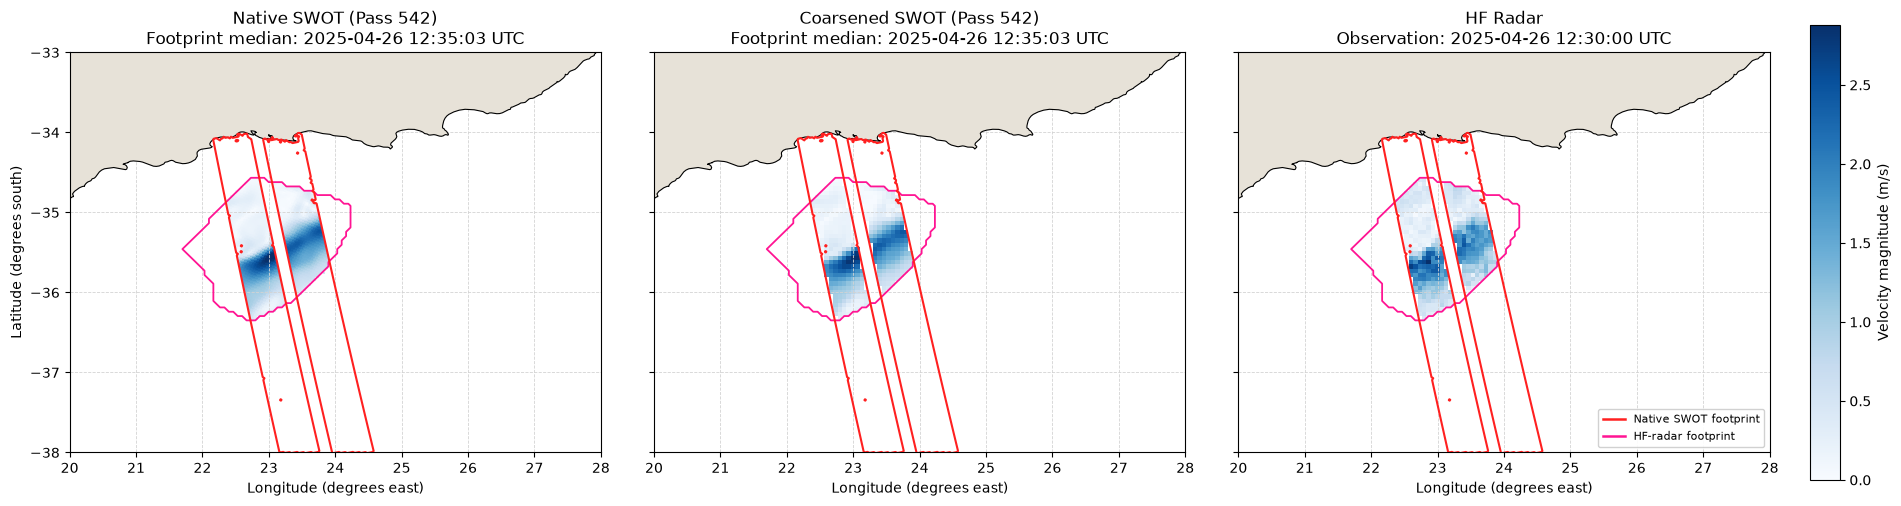

In [ ]:
# Plot the requested SWOT overpass with a legend on the right-hand map.

target_record = next(
    (
        record for record in processed_manifest
        if record['cycle'] == 31 and record['pass'] == 542
        and record['swot_time'] == pd.Timestamp('2025-04-26 11:59:01')
    ),
    None,
)

if target_record is None:
    raise ValueError('Requested overpass was not found in processed_manifest.')

with xr.open_dataset(target_record['file_native']) as ds_native:
    lon_native = ds_native['longitude'].values
    lat_native = ds_native['latitude'].values
    speed_native = ds_native['speed_masked'].values
    swot_valid = ds_native['swot_valid_mask'].values
    swot_footprint_time = pd.to_datetime(ds_native.attrs['swot_domain_time'])

with xr.open_dataset(target_record['file_coarse']) as ds_coarse:
    radar_lon = ds_coarse['longitude'].values
    radar_lat = ds_coarse['latitude'].values
    speed_coarse = ds_coarse['speed_coarsened_masked'].values

with xr.open_dataset(target_record['file_radar']) as ds_radar:
    speed_radar = ds_radar['speed_masked'].values
    radar_valid = ds_radar['radar_valid_mask'].values
    radar_observation_time = pd.to_datetime(ds_radar.attrs['matched_radar_time'])

valid_speeds = np.concatenate([
    values[np.isfinite(values)]
    for values in (speed_native, speed_coarse, speed_radar)
    if np.isfinite(values).any()
])
colour_limit = float(np.nanpercentile(valid_speeds, 99.5))
colour_limit = max(colour_limit, 1.0)

print(f'SWOT median time over HF-radar footprint: {swot_footprint_time:%Y-%m-%d %H:%M:%S} UTC')
print(f'HF-radar observation time: {radar_observation_time:%Y-%m-%d %H:%M:%S} UTC')
print(f'SWOT-HF-radar time gap: {abs(radar_observation_time - swot_footprint_time)}')

figure, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)

panel_data = [
    (
        speed_native,
        lon_native,
        lat_native,
        f"Native SWOT (Pass 542)\nFootprint median: {swot_footprint_time:%Y-%m-%d %H:%M:%S} UTC",
    ),
    (
        speed_coarse,
        radar_lon,
        radar_lat,
        f"Coarsened SWOT (Pass 542)\nFootprint median: {swot_footprint_time:%Y-%m-%d %H:%M:%S} UTC",
    ),
    (
        speed_radar,
        radar_lon,
        radar_lat,
        f"HF Radar\nObservation: {radar_observation_time:%Y-%m-%d %H:%M:%S} UTC",
    ),
]

for axis, (speed, longitude, latitude, title) in zip(axes, panel_data):
    land.plot(ax=axis, color='#e7e2d8', zorder=2)
    land.boundary.plot(ax=axis, color='black', linewidth=0.8, zorder=3)
    axis.pcolormesh(
        longitude,
        latitude,
        speed,
        cmap='Blues',
        vmin=0,
        vmax=colour_limit,
        shading='nearest',
        zorder=1,
    )
    axis.set_xlim(PLOT_BBOX[0], PLOT_BBOX[1])
    axis.set_ylim(PLOT_BBOX[2], PLOT_BBOX[3])
    axis.set_title(title)
    axis.set_xlabel('Longitude (degrees east)')
    axis.grid(color='lightgrey', linestyle='--', linewidth=0.6)

# Footprint outlines.
axes[0].contour(
    lon_native, lat_native, swot_valid.astype(float),
    levels=[0.5], colors='#ff2020', linewidths=1.5, zorder=5,
)
for axis in axes[1:]:
    axis.contour(
        lon_native, lat_native, swot_valid.astype(float),
        levels=[0.5], colors='#ff2020', linewidths=1.5, zorder=5,
    )

for axis in axes:
    axis.contour(
        radar_lon, radar_lat, radar_valid.astype(float),
        levels=[0.5], colors='deeppink', linewidths=1.3, zorder=4,
    )

axes[0].set_ylabel('Latitude (degrees south)')

colourbar_axis = figure.add_axes([0.92, 0.15, 0.015, 0.7])
figure.colorbar(
    plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=0, vmax=colour_limit),
        cmap='Blues',
    ),
    cax=colourbar_axis,
    label='Velocity magnitude (m/s)',
)

legend_handles = [
    plt.Line2D([], [], color='#ff2020', linewidth=1.8, label='Native SWOT footprint'),
    plt.Line2D([], [], color='deeppink', linewidth=1.8, label='HF-radar footprint'),
]
axes[2].legend(
    handles=legend_handles,
    loc='lower right',
    fontsize=8,
    framealpha=0.9,
)

figure.subplots_adjust(
    left=0.05,
    right=0.90,
    bottom=0.12,
    top=0.88,
    wspace=0.10,
)
plt.show()

## 4. Matched comparison counts on the 6 km HF-radar grid

Load every generated triplet in `data/processed/swot_hfradar_matches` and, for each cell of the common 6 km radar grid, count how many overpasses passed the full matching pipeline (radar file within 3 hours, minimum SWOT pixel threshold, mutual valid coverage) and contributed a valid coarsened-SWOT/HF-radar comparison. This is a count of matched, quality-screened comparison instances, not the raw number of SWOT or HF-radar observations available in the domain.

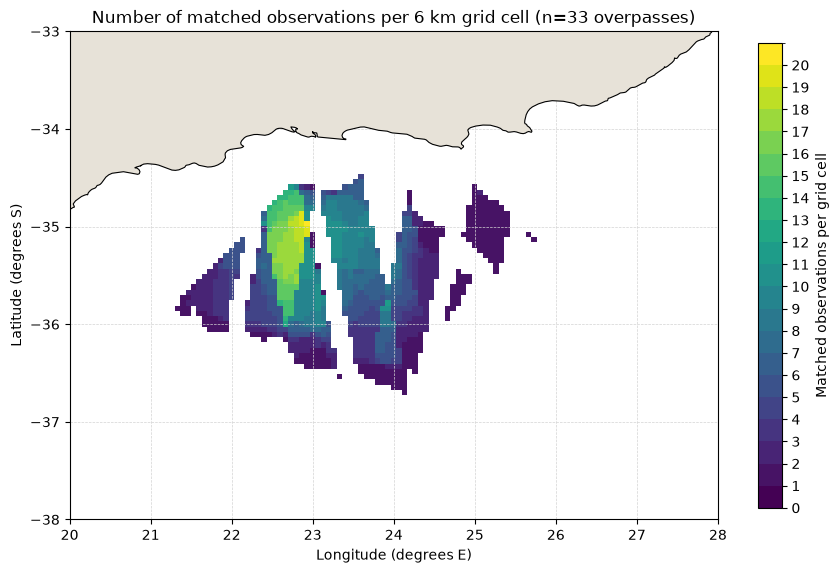

Overpasses included: 33
Grid shape: 75 lat x 150 lon (6 km resolution)
Grid cells with at least 1 matched observation: 1,127
Maximum matched observations in a single cell: 20


In [24]:
# Count matched SWOT-HF-radar observations per 6 km grid cell across all overpasses.

coarse_files = sorted(DIR_COARSE.glob('swot_coarsened_masked_*.nc'))
radar_files_processed = sorted(DIR_RADAR.glob('hfradar_swot_masked_*.nc'))

if not coarse_files or not radar_files_processed:
    raise FileNotFoundError(f"No processed files found in {DIR_COARSE} or {DIR_RADAR}. Run the generation pipeline above first.")

# The 6 km radar grid is identical across all processed files; take it from the first coarsened file.
with xr.open_dataset(coarse_files[0]) as ds0:
    grid_latitude = ds0['latitude'].values
    grid_longitude = ds0['longitude'].values

if len(coarse_files) != len(radar_files_processed):
    raise ValueError('The coarsened SWOT and HF-radar file counts do not match.')

matched_observation_count = np.zeros((grid_latitude.size, grid_longitude.size), dtype=int)

for file_coarse, file_radar in zip(coarse_files, radar_files_processed):
    with xr.open_dataset(file_coarse) as ds_coarse:
        coarse_speed = ds_coarse['speed_coarsened_masked'].values
    with xr.open_dataset(file_radar) as ds_radar:
        radar_speed = ds_radar['speed_masked'].values

    paired_valid = np.isfinite(coarse_speed) & np.isfinite(radar_speed)
    matched_observation_count += paired_valid.astype(int)

number_of_overpasses = len(coarse_files)
maximum_matched_observations = int(matched_observation_count.max())
count_plot = np.where(matched_observation_count > 0, matched_observation_count, np.nan)
count_lat_edges = centre_edges(grid_latitude)
count_lon_edges = centre_edges(grid_longitude)

# Scale the colourbar to the observed maximum number of matched observations per cell.
count_levels = np.arange(0, maximum_matched_observations + 2)
count_cmap = plt.get_cmap('viridis', len(count_levels) - 1)
count_norm = mcolors.BoundaryNorm(count_levels, count_cmap.N)

figure, axis = plt.subplots(figsize=(9, 6))
land.plot(ax=axis, color='#e7e2d8', zorder=2)
land.boundary.plot(ax=axis, color='black', linewidth=0.8, zorder=3)
mesh = axis.pcolormesh(
    count_lon_edges,
    count_lat_edges,
    count_plot,
    cmap=count_cmap,
    norm=count_norm,
    zorder=1,
)
axis.set_xlim(PLOT_BBOX[0], PLOT_BBOX[1])
axis.set_ylim(PLOT_BBOX[2], PLOT_BBOX[3])
axis.set_title(
    f'Number of matched observations per 6 km grid cell (n={number_of_overpasses} overpasses)'
)
axis.set_xlabel('Longitude (degrees E)')
axis.set_ylabel('Latitude (degrees S)')
axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
figure.colorbar(
    mesh,
    ax=axis,
    ticks=np.arange(0, maximum_matched_observations + 1),
    label='Matched observations per grid cell',
    shrink=0.85,
)
figure.tight_layout()
plt.show()

print(f'Overpasses included: {number_of_overpasses}')
print(f'Grid shape: {grid_latitude.size} lat x {grid_longitude.size} lon (6 km resolution)')
print(f'Grid cells with at least 1 matched observation: {(matched_observation_count > 0).sum():,}')
print(f'Maximum matched observations in a single cell: {maximum_matched_observations}')

In [5]:
# Gather matched triplets and compute error statistics between coarsened SWOT and HF radar

native_files_all = sorted(DIR_NATIVE.glob('swot_native_masked_*.nc'))
matched_triplets = []
for file_native in native_files_all:
    m = re.search(r'swot_native_masked_(c\d{3}_p\d{3}_\d{8}T\d{6})\.nc', file_native.name)
    if not m:
        continue
    stem = m.group(1)
    file_coarse = DIR_COARSE / f'swot_coarsened_masked_{stem}.nc'
    file_radar = DIR_RADAR / f'hfradar_swot_masked_{stem}.nc'
    if file_coarse.exists() and file_radar.exists():
        matched_triplets.append((file_native, file_coarse, file_radar))

if not matched_triplets:
    raise FileNotFoundError('No matched triplets found. Run the generation pipeline above first.')

native_speed_values = []
coarse_speed_values = []
radar_speed_values = []
coarse_paired_values = []
radar_paired_values = []

for file_native, file_coarse, file_radar in matched_triplets:
    with xr.open_dataset(file_native) as ds_native:
        native_speed_values.append(ds_native['speed_masked'].values.ravel())
    with xr.open_dataset(file_coarse) as ds_coarse:
        coarse_speed = ds_coarse['speed_coarsened_masked'].values
    with xr.open_dataset(file_radar) as ds_radar:
        radar_speed = ds_radar['speed_masked'].values

    coarse_speed_values.append(coarse_speed.ravel())
    radar_speed_values.append(radar_speed.ravel())

    # Coarsened SWOT and HF radar share the same 6 km grid, so cells pair up directly
    paired_valid = np.isfinite(coarse_speed) & np.isfinite(radar_speed)
    coarse_paired_values.append(coarse_speed[paired_valid])
    radar_paired_values.append(radar_speed[paired_valid])

native_speed_values = np.concatenate(native_speed_values)
native_speed_values = native_speed_values[np.isfinite(native_speed_values)]
coarse_speed_values = np.concatenate(coarse_speed_values)
coarse_speed_values = coarse_speed_values[np.isfinite(coarse_speed_values)]
radar_speed_values = np.concatenate(radar_speed_values)
radar_speed_values = radar_speed_values[np.isfinite(radar_speed_values)]

coarse_paired_values = np.concatenate(coarse_paired_values)
radar_paired_values = np.concatenate(radar_paired_values)
speed_diff_values = coarse_paired_values - radar_paired_values

bias = float(np.mean(speed_diff_values))
rmse = float(np.sqrt(np.mean(speed_diff_values ** 2)))
std_diff = float(np.std(speed_diff_values))
correlation = float(np.corrcoef(coarse_paired_values, radar_paired_values)[0, 1]) if coarse_paired_values.size > 1 else np.nan

print(f'Matched triplets: {len(matched_triplets)}')
print(f'Native SWOT valid pixels: {native_speed_values.size:,}')
print(f'Coarsened SWOT valid cells: {coarse_speed_values.size:,}')
print(f'HF-radar valid cells: {radar_speed_values.size:,}')
print(f'Paired coarsened-SWOT/HF-radar comparisons: {coarse_paired_values.size:,}')
print(f'Bias (coarsened SWOT - HF radar): {bias:.4f} m/s')
print(f'RMSE: {rmse:.4f} m/s')
print(f'Std of differences: {std_diff:.4f} m/s')
print(f'Correlation coefficient: {correlation:.4f}')


Matched triplets: 33
Native SWOT valid pixels: 61,481
Coarsened SWOT valid cells: 6,405
HF-radar valid cells: 6,405
Paired coarsened-SWOT/HF-radar comparisons: 6,405
Bias (coarsened SWOT - HF radar): -0.0993 m/s
RMSE: 0.3851 m/s
Std of differences: 0.3721 m/s
Correlation coefficient: 0.8115


# Overpass time series of absolute and relative coarsened-SWOT versus HF-radar RMSE.


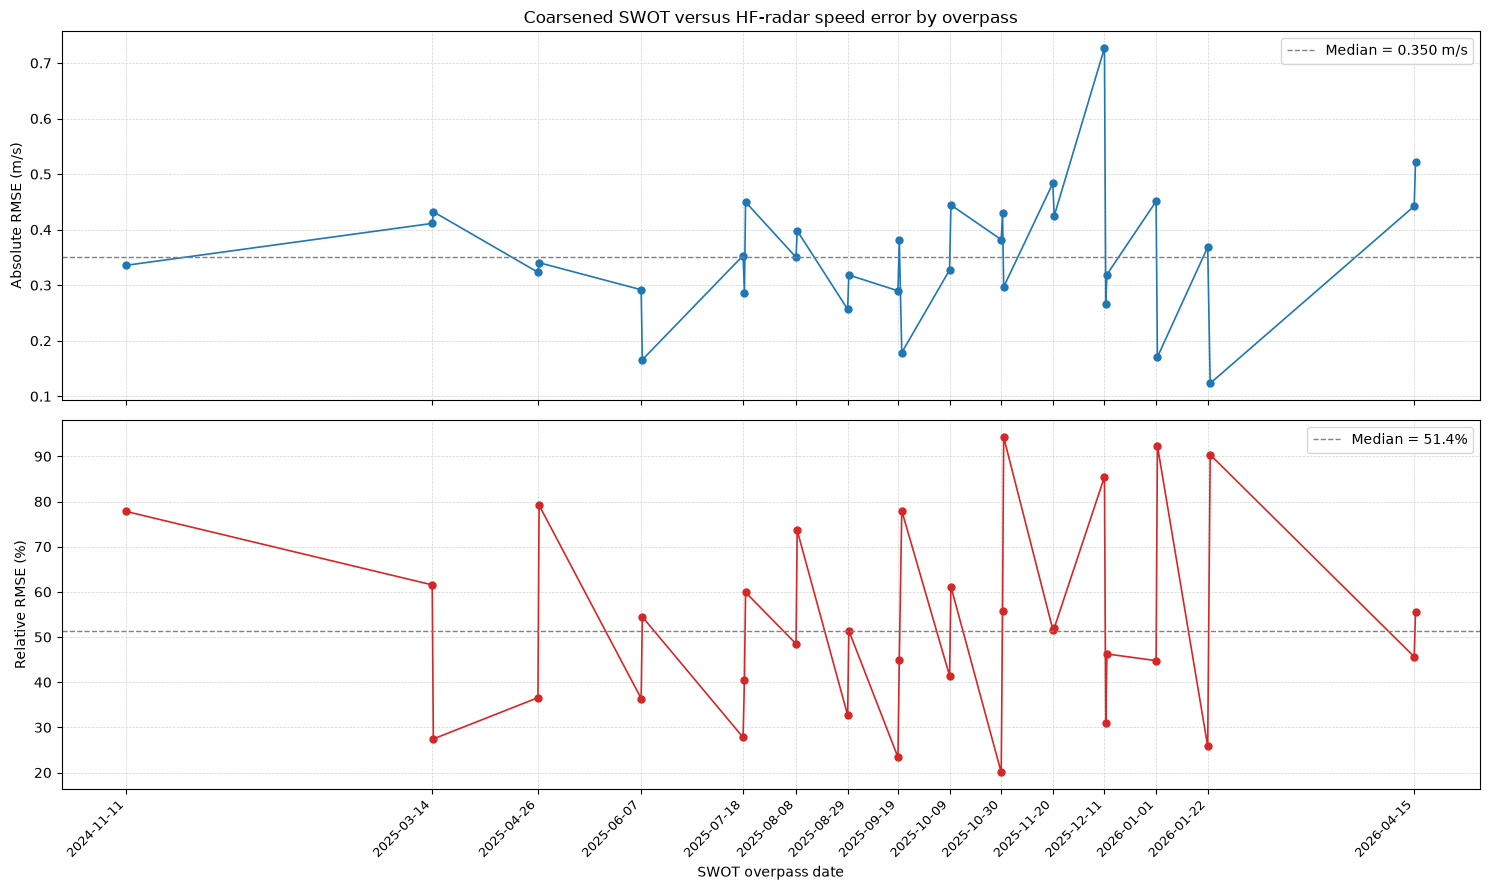

Overpasses plotted: 33
Dates labelled: 15
Absolute RMSE range: 0.123–0.727 m/s
Relative RMSE range: 20.0–94.2%


In [6]:
# Overpass time series of absolute and relative coarsened-SWOT versus HF-radar RMSE.

MIN_REFERENCE_SPEED = 0.05  # m/s; exclude near-zero speeds from relative RMSE
OVERPASS_CLUSTER_GAP = pd.Timedelta(days=7)

overpass_times = []
overpass_rmse = []
overpass_relative_rmse = []
overpass_pair_counts = []

for file_native, file_coarse, file_radar in matched_triplets:
    with xr.open_dataset(file_native) as ds_native:
        overpass_time = pd.to_datetime(ds_native.attrs['swot_time'])

    with xr.open_dataset(file_coarse) as ds_coarse:
        coarse_speed = ds_coarse['speed_coarsened_masked'].values

    with xr.open_dataset(file_radar) as ds_radar:
        radar_speed = ds_radar['speed_masked'].values

    paired_valid = np.isfinite(coarse_speed) & np.isfinite(radar_speed)
    coarse_values = coarse_speed[paired_valid]
    radar_values = radar_speed[paired_valid]

    if coarse_values.size == 0:
        continue

    differences = coarse_values - radar_values
    reference_speed = (coarse_values + radar_values) / 2
    valid_reference = reference_speed >= MIN_REFERENCE_SPEED

    overpass_times.append(overpass_time)
    overpass_rmse.append(np.sqrt(np.mean(differences ** 2)))
    overpass_pair_counts.append(coarse_values.size)

    if valid_reference.any():
        relative_rmse = (
            100
            * np.sqrt(np.mean(differences[valid_reference] ** 2))
            / np.mean(reference_speed[valid_reference])
        )
    else:
        relative_rmse = np.nan

    overpass_relative_rmse.append(relative_rmse)

order = np.argsort(overpass_times)
overpass_times = np.asarray(overpass_times, dtype='datetime64[ns]')[order]
overpass_rmse = np.asarray(overpass_rmse)[order]
overpass_relative_rmse = np.asarray(overpass_relative_rmse)[order]
overpass_pair_counts = np.asarray(overpass_pair_counts)[order]

# Label only the first overpass in each cluster separated by more than seven days.
overpass_timestamps = pd.to_datetime(overpass_times)
date_label_indices = [0]
for index in range(1, len(overpass_timestamps)):
    if overpass_timestamps[index] - overpass_timestamps[index - 1] > OVERPASS_CLUSTER_GAP:
        date_label_indices.append(index)

date_label_indices = np.asarray(date_label_indices)
overpass_tick_dates = overpass_times[date_label_indices]
overpass_tick_labels = pd.to_datetime(overpass_tick_dates).strftime('%Y-%m-%d')

figure, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

axes[0].plot(
    overpass_times,
    overpass_rmse,
    'o-',
    color='#1f77b4',
    linewidth=1.2,
    markersize=5,
)
axes[0].axhline(
    np.nanmedian(overpass_rmse),
    color='grey',
    linestyle='--',
    linewidth=1,
    label=f'Median = {np.nanmedian(overpass_rmse):.3f} m/s',
)
axes[0].set_ylabel('Absolute RMSE (m/s)')
axes[0].set_title('Coarsened SWOT versus HF-radar speed error by overpass')
axes[0].grid(color='lightgrey', linestyle='--', linewidth=0.5)
axes[0].legend()

axes[1].plot(
    overpass_times,
    overpass_relative_rmse,
    'o-',
    color='#d62728',
    linewidth=1.2,
    markersize=5,
)
axes[1].axhline(
    np.nanmedian(overpass_relative_rmse),
    color='grey',
    linestyle='--',
    linewidth=1,
    label=f'Median = {np.nanmedian(overpass_relative_rmse):.1f}%',
)
axes[1].set_ylabel('Relative RMSE (%)')
axes[1].set_xlabel('SWOT overpass date')
axes[1].set_xticks(overpass_tick_dates)
axes[1].set_xticklabels(overpass_tick_labels, rotation=45, ha='right', fontsize=9)
axes[1].grid(color='lightgrey', linestyle='--', linewidth=0.5)
axes[1].legend()

figure.tight_layout()
plt.show()

print(f'Overpasses plotted: {len(overpass_times)}')
print(f'Dates labelled: {len(overpass_tick_dates)}')
print(f'Absolute RMSE range: {np.nanmin(overpass_rmse):.3f}–{np.nanmax(overpass_rmse):.3f} m/s')
print(f'Relative RMSE range: {np.nanmin(overpass_relative_rmse):.1f}–{np.nanmax(overpass_relative_rmse):.1f}%')

**?? Re the above, why are there so few matches between 11 Nov 24 and 14 Mar 25 and 22 Jan 26 and 15 Apr 26?**

# Native SWOT, paired coarsened-SWOT, and HF-radar speed distributions and signed speed bias.


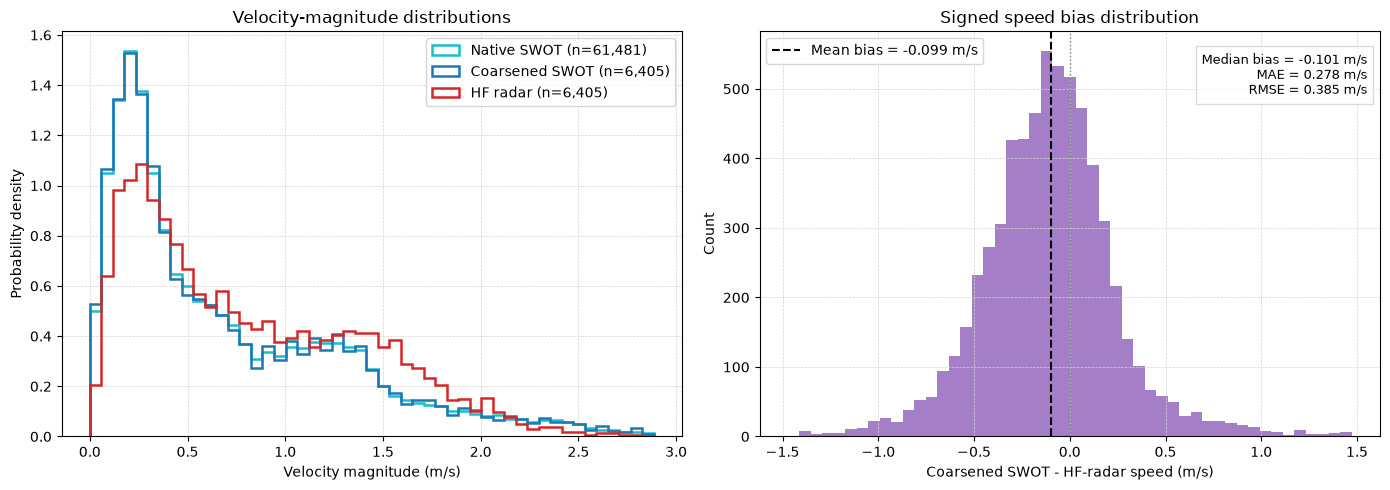

Native SWOT masked pixels: 61,481
Paired comparisons: 6,405
Mean bias: -0.0993 m/s
Median bias: -0.1009 m/s
MAE: 0.2785 m/s
RMSE: 0.3851 m/s


In [7]:
# Native SWOT, paired coarsened-SWOT, and HF-radar speed distributions and signed speed bias.

histogram_speed_limit = float(np.nanpercentile(
    np.concatenate((native_speed_values, coarse_paired_values, radar_paired_values)),
    99.5,
))
histogram_speed_bins = np.linspace(0, histogram_speed_limit, 50)
bias_limit = float(np.nanpercentile(np.abs(speed_diff_values), 99.5))
bias_bins = np.linspace(-bias_limit, bias_limit, 50)
median_bias = float(np.median(speed_diff_values))
mae = float(np.mean(np.abs(speed_diff_values)))

figure, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    native_speed_values,
    bins=histogram_speed_bins,
    histtype='step',
    linewidth=1.8,
    density=True,
    label=f'Native SWOT (n={native_speed_values.size:,})',
    color='#17becf',
)
axes[0].hist(
    coarse_paired_values,
    bins=histogram_speed_bins,
    histtype='step',
    linewidth=1.8,
    density=True,
    label=f'Coarsened SWOT (n={coarse_paired_values.size:,})',
    color='#1f77b4',
)
axes[0].hist(
    radar_paired_values,
    bins=histogram_speed_bins,
    histtype='step',
    linewidth=1.8,
    density=True,
    label=f'HF radar (n={radar_paired_values.size:,})',
    color='#d62728',
)
axes[0].set_xlabel('Velocity magnitude (m/s)')
axes[0].set_ylabel('Probability density')
axes[0].set_title('Velocity-magnitude distributions')
axes[0].grid(color='lightgrey', linestyle='--', linewidth=0.5)
axes[0].legend()

axes[1].hist(speed_diff_values, bins=bias_bins, color='#9467bd', alpha=0.85)
axes[1].axvline(
    bias,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label=f'Mean bias = {bias:.3f} m/s',
)
axes[1].axvline(0, color='grey', linestyle=':', linewidth=1)
axes[1].text(
    0.98,
    0.95,
    f'Median bias = {median_bias:.3f} m/s\nMAE = {mae:.3f} m/s\nRMSE = {rmse:.3f} m/s',
    transform=axes[1].transAxes,
    ha='right',
    va='top',
    fontsize=9,
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='lightgrey'),
)
axes[1].set_xlabel('Coarsened SWOT - HF-radar speed (m/s)')
axes[1].set_ylabel('Count')
axes[1].set_title('Signed speed bias distribution')
axes[1].grid(color='lightgrey', linestyle='--', linewidth=0.5)
axes[1].legend()

figure.tight_layout()
plt.show()

print(f'Native SWOT masked pixels: {native_speed_values.size:,}')
print(f'Paired comparisons: {speed_diff_values.size:,}')
print(f'Mean bias: {bias:.4f} m/s')
print(f'Median bias: {median_bias:.4f} m/s')
print(f'MAE: {mae:.4f} m/s')
print(f'RMSE: {rmse:.4f} m/s')

 # Global paired statistics for coarsened SWOT versus HF-radar speed.


In [8]:
# Global paired statistics for coarsened SWOT versus HF-radar speed.

median_bias = float(np.median(speed_diff_values))
mae = float(np.mean(np.abs(speed_diff_values)))
limits_of_agreement_lower = bias - 1.96 * std_diff
limits_of_agreement_upper = bias + 1.96 * std_diff

paired_metric_table = pd.DataFrame(
    {
        'Metric': [
            'Paired observations',
            'Mean bias',
            'Median bias',
            'Mean absolute error',
            'Root mean square error',
            'Standard deviation of differences',
            'Pearson correlation coefficient',
            '95% limits of agreement',
        ],
        'Value': [
            f'{speed_diff_values.size:,}',
            f'{bias:.4f} m/s',
            f'{median_bias:.4f} m/s',
            f'{mae:.4f} m/s',
            f'{rmse:.4f} m/s',
            f'{std_diff:.4f} m/s',
            f'{correlation:.4f}',
            f'{limits_of_agreement_lower:.4f} to {limits_of_agreement_upper:.4f} m/s',
        ],
        'Purpose': [
            'Effective sample size',
            'Signed systematic difference',
            'Robust central difference',
            'Typical absolute discrepancy',
            'Error including large deviations',
            'Random disagreement',
            'Linear association',
            'Expected range for individual paired differences',
        ],
    }
)

paired_metric_table

,Metric,Value,Purpose
0,Paired observations,"6,405",Effective sample size
1,Mean bias,-0.0993 m/s,Signed systematic difference
2,Median bias,-0.1009 m/s,Robust central difference
3,Mean absolute error,0.2785 m/s,Typical absolute discrepancy
4,Root mean square error,0.3851 m/s,Error including large deviations
5,Standard deviation of differences,0.3721 m/s,Random disagreement
6,Pearson correlation coefficient,0.8115,Linear association
7,95% limits of agreement,-0.8286 to 0.6300 m/s,Expected range for individual paired differences


# Bland-Altman plot for paired coarsened-SWOT and HF-radar speed.

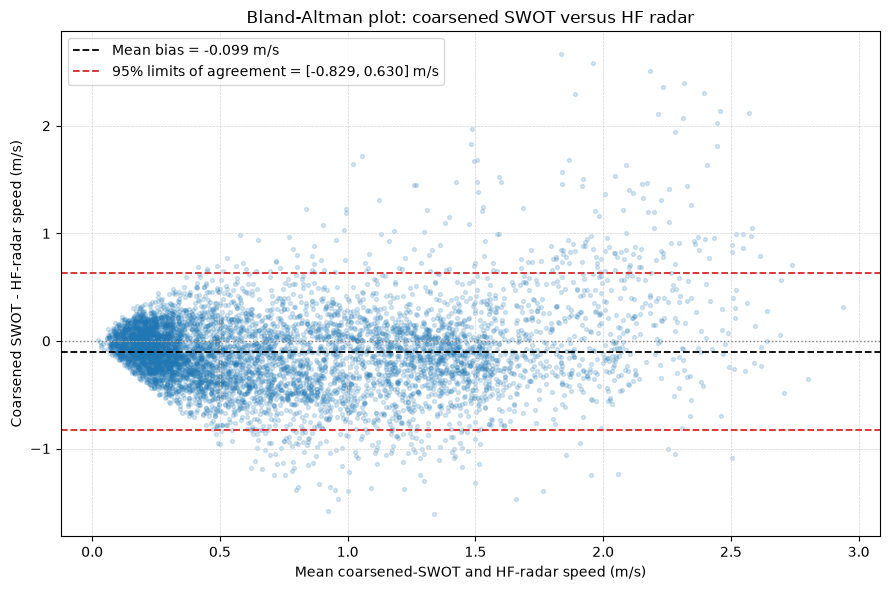

In [9]:
# Bland-Altman plot for paired coarsened-SWOT and HF-radar speed.

pair_mean_speed = (coarse_paired_values + radar_paired_values) / 2

figure, axis = plt.subplots(figsize=(9, 6))
axis.scatter(
    pair_mean_speed,
    speed_diff_values,
    s=8,
    alpha=0.18,
    color='#1f77b4',
    rasterized=True,
)
axis.axhline(0, color='grey', linestyle=':', linewidth=1)
axis.axhline(
    bias,
    color='black',
    linestyle='--',
    linewidth=1.3,
    label=f'Mean bias = {bias:.3f} m/s',
)
axis.axhline(
    limits_of_agreement_upper,
    color='#d62728',
    linestyle='--',
    linewidth=1.3,
    label=f'95% limits of agreement = [{limits_of_agreement_lower:.3f}, {limits_of_agreement_upper:.3f}] m/s',
)
axis.axhline(
    limits_of_agreement_lower,
    color='#d62728',
    linestyle='--',
    linewidth=1.3,
)
axis.set_xlabel('Mean coarsened-SWOT and HF-radar speed (m/s)')
axis.set_ylabel('Coarsened SWOT - HF-radar speed (m/s)')
axis.set_title('Bland-Altman plot: coarsened SWOT versus HF radar')
axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
axis.legend()
figure.tight_layout()
plt.show()

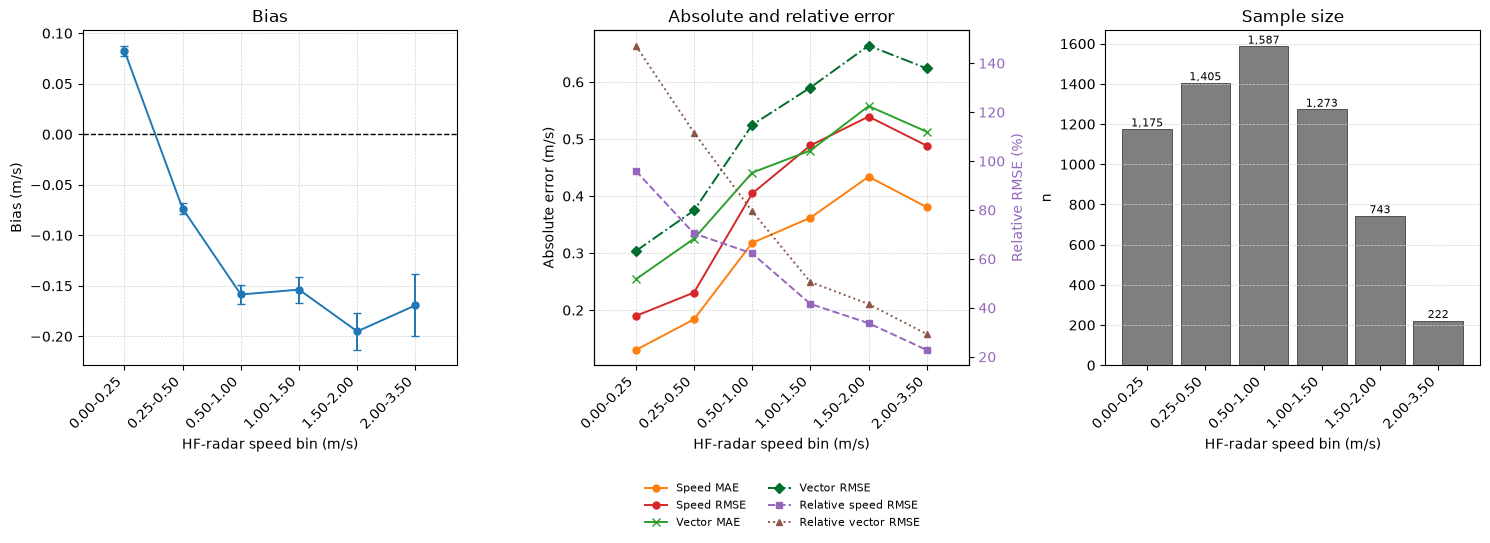

Speed bins: 0.00-0.25; 0.25-0.50; 0.50-1.00; 1.00-1.50; 1.50-2.00; 2.00-3.50 m/s
Observations with HF-radar speed >= 2.5 m/s: 28
Bins with observations: 6 of 6
Total paired observations in bins: 6,405


In [26]:
# Primary figure: performance as a function of HF-radar speed

speed_bin_edges = np.array([0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.5])
speed_bin_labels = [
    '0.00-0.25',
    '0.25-0.50',
    '0.50-1.00',
    '1.00-1.50',
    '1.50-2.00',
    '2.00-3.50',
]
speed_bin_positions = np.arange(len(speed_bin_labels))

speed_bin_bias = np.full(speed_bin_positions.size, np.nan)
speed_bin_mae = np.full(speed_bin_positions.size, np.nan)
speed_bin_rmse = np.full(speed_bin_positions.size, np.nan)
speed_bin_relative_rmse = np.full(speed_bin_positions.size, np.nan)
speed_bin_vector_mae = np.full(speed_bin_positions.size, np.nan)
speed_bin_vector_rmse = np.full(speed_bin_positions.size, np.nan)
speed_bin_relative_vector_rmse = np.full(speed_bin_positions.size, np.nan)
speed_bin_bias_sem = np.full(speed_bin_positions.size, np.nan)
speed_bin_n = np.zeros(speed_bin_positions.size, dtype=int)
MIN_VECTOR_SPEED = 0.05  # m/s; require both vector magnitudes above this threshold

for bin_index in range(speed_bin_positions.size):
    is_final_bin = bin_index == speed_bin_positions.size - 1
    in_bin = (
        (radar_paired_values >= speed_bin_edges[bin_index])
        & (
            (radar_paired_values <= speed_bin_edges[bin_index + 1])
            if is_final_bin else
            (radar_paired_values < speed_bin_edges[bin_index + 1])
        )
        & np.isfinite(speed_diff_values)
    )
    differences = speed_diff_values[in_bin]
    reference_speeds = (coarse_paired_values[in_bin] + radar_paired_values[in_bin]) / 2
    speed_bin_n[bin_index] = differences.size

    if differences.size:
        speed_bin_bias[bin_index] = np.mean(differences)
        speed_bin_mae[bin_index] = np.mean(np.abs(differences))
        speed_bin_rmse[bin_index] = np.sqrt(np.mean(differences ** 2))
        valid_reference = reference_speeds >= MIN_REFERENCE_SPEED
        if valid_reference.any():
            speed_bin_relative_rmse[bin_index] = (
                100
                * np.sqrt(np.mean(differences[valid_reference] ** 2))
                / np.mean(reference_speeds[valid_reference])
            )
        if differences.size > 1:
            speed_bin_bias_sem[bin_index] = (
                np.std(differences, ddof=1) / np.sqrt(differences.size)
            )

# Compute vector MAE, vector RMSE, and relative vector RMSE in the same bins.
vector_absolute_errors_by_bin = [[] for _ in speed_bin_positions]
vector_squared_errors_by_bin = [[] for _ in speed_bin_positions]
vector_reference_speeds_by_bin = [[] for _ in speed_bin_positions]
for _, file_coarse, file_radar in matched_triplets:
    with xr.open_dataset(file_coarse) as ds_coarse:
        coarse_u = ds_coarse['ugos_coarsened_raw'].values
        coarse_v = ds_coarse['vgos_coarsened_raw'].values
    with xr.open_dataset(file_radar) as ds_radar:
        radar_u = ds_radar['ewct_raw'].values
        radar_v = ds_radar['nsct_raw'].values

    coarse_speed = np.hypot(coarse_u, coarse_v)
    radar_speed = np.hypot(radar_u, radar_v)
    vector_valid = (
        np.isfinite(coarse_u)
        & np.isfinite(coarse_v)
        & np.isfinite(radar_u)
        & np.isfinite(radar_v)
        & (coarse_speed >= MIN_VECTOR_SPEED)
        & (radar_speed >= MIN_VECTOR_SPEED)
    )
    squared_vector_error = (coarse_u - radar_u) ** 2 + (coarse_v - radar_v) ** 2
    absolute_vector_error = np.sqrt(squared_vector_error)
    vector_reference_speed = (coarse_speed + radar_speed) / 2

    for bin_index in range(speed_bin_positions.size):
        is_final_bin = bin_index == speed_bin_positions.size - 1
        in_speed_bin = (
            (radar_speed >= speed_bin_edges[bin_index])
            & (
                (radar_speed <= speed_bin_edges[bin_index + 1])
                if is_final_bin else
                (radar_speed < speed_bin_edges[bin_index + 1])
            )
            & vector_valid
        )
        vector_absolute_errors_by_bin[bin_index].append(absolute_vector_error[in_speed_bin])
        vector_squared_errors_by_bin[bin_index].append(squared_vector_error[in_speed_bin])
        vector_reference_speeds_by_bin[bin_index].append(vector_reference_speed[in_speed_bin])

for bin_index, (absolute_errors, squared_errors, reference_speeds) in enumerate(
    zip(
        vector_absolute_errors_by_bin,
        vector_squared_errors_by_bin,
        vector_reference_speeds_by_bin,
    )
):
    if absolute_errors:
        concatenated_absolute_errors = np.concatenate(absolute_errors)
        concatenated_squared_errors = np.concatenate(squared_errors)
        concatenated_reference_speeds = np.concatenate(reference_speeds)
        if concatenated_absolute_errors.size:
            speed_bin_vector_mae[bin_index] = np.mean(concatenated_absolute_errors)
            speed_bin_vector_rmse[bin_index] = np.sqrt(np.mean(concatenated_squared_errors))
            speed_bin_relative_vector_rmse[bin_index] = (
                100
                * speed_bin_vector_rmse[bin_index]
                / np.mean(concatenated_reference_speeds)
            )

figure, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharex=True)

# Bias
axes[0].errorbar(
    speed_bin_positions,
    speed_bin_bias,
    yerr=speed_bin_bias_sem,
    fmt='o-',
    capsize=3,
    color='#1f77b4',
    linewidth=1.4,
    markersize=5,
)
axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0].set_ylabel('Bias (m/s)')
axes[0].set_title('Bias')
axes[0].grid(color='lightgrey', linestyle='--', linewidth=0.5)

# Absolute, relative, and vector errors
absolute_error_axis = axes[1]
absolute_error_axis.plot(
    speed_bin_positions,
    speed_bin_mae,
    'o-',
    color='#ff7f0e',
    linewidth=1.4,
    markersize=5,
    label='Speed MAE',
)
absolute_error_axis.plot(
    speed_bin_positions,
    speed_bin_rmse,
    'o-',
    color='#d62728',
    linewidth=1.4,
    markersize=5,
    label='Speed RMSE',
)
absolute_error_axis.plot(
    speed_bin_positions,
    speed_bin_vector_mae,
    'x-',
    color='#2ca02c',
    linewidth=1.4,
    markersize=6,
    label='Vector MAE',
)
absolute_error_axis.plot(
    speed_bin_positions,
    speed_bin_vector_rmse,
    'D-.',
    color='#006d2c',
    linewidth=1.4,
    markersize=5,
    label='Vector RMSE',
)
absolute_error_axis.set_ylabel('Absolute error (m/s)')
absolute_error_axis.set_title('Absolute and relative error')
absolute_error_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)

relative_error_axis = absolute_error_axis.twinx()
relative_error_axis.plot(
    speed_bin_positions,
    speed_bin_relative_rmse,
    's--',
    color='#9467bd',
    linewidth=1.4,
    markersize=5,
    label='Relative speed RMSE',
)
relative_error_axis.plot(
    speed_bin_positions,
    speed_bin_relative_vector_rmse,
    '^:',
    color='#8c564b',
    linewidth=1.4,
    markersize=5,
    label='Relative vector RMSE',
)
relative_error_axis.set_ylabel('Relative RMSE (%)', color='#9467bd')
relative_error_axis.tick_params(axis='y', labelcolor='#9467bd')

absolute_handles, absolute_labels = absolute_error_axis.get_legend_handles_labels()
relative_handles, relative_labels = relative_error_axis.get_legend_handles_labels()
figure.legend(
    absolute_handles + relative_handles,
    absolute_labels + relative_labels,
    loc='lower center',
    bbox_to_anchor=(0.525, 0.01),
    ncol=2,
    frameon=False,
    fontsize=8,
)

# Sample size
axes[2].bar(
    speed_bin_positions,
    speed_bin_n,
    width=0.85,
    color='#7f7f7f',
    edgecolor='black',
    linewidth=0.4,
)
for bin_position, observation_count in zip(speed_bin_positions, speed_bin_n):
    if observation_count > 0:
        axes[2].text(
            bin_position,
            observation_count,
            f'{observation_count:,}',
            ha='center',
            va='bottom',
            fontsize=8,
        )
axes[2].set_ylabel('n')
axes[2].set_title('Sample size')
axes[2].grid(axis='y', color='lightgrey', linestyle='--', linewidth=0.5)

for axis in axes:
    axis.set_xlabel('HF-radar speed bin (m/s)')
    axis.set_xticks(speed_bin_positions)
    axis.set_xticklabels(speed_bin_labels, rotation=45, ha='right')

figure.subplots_adjust(bottom=0.32)
figure.tight_layout(rect=[0, 0.14, 1, 1])
plt.show()

print(f'Speed bins: {"; ".join(speed_bin_labels)} m/s')
print(f'Observations with HF-radar speed >= 2.5 m/s: {np.count_nonzero((radar_paired_values >= 2.5) & np.isfinite(speed_diff_values)):,}')
print(f'Bins with observations: {(speed_bin_n > 0).sum()} of {speed_bin_n.size}')
print(f'Total paired observations in bins: {speed_bin_n.sum():,}')

### Spatial distribution of relative vector RMSE and signed speed bias

For each cell of the common 6 km grid, accumulate vector errors across all matched overpasses. The relative vector RMSE and mean signed speed bias are shown in separate figures using all valid paired observations.

HDF5-DIAG: Error detected in HDF5 (2.1.0) thread 211:
  #000: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5F.c line 821 in H5Fopen(): unable to synchronously open file
    major: File accessibility
    minor: Unable to open file
  #001: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5F.c line 782 in H5F__open_api_common(): unable to open file
    major: File accessibility
    minor: Unable to open file
  #002: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5VLcallback.c line 3869 in H5VL_file_open(): open failed
    major: Virtual Object Layer
    minor: Can't open object
  #003: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5VLcallback.c line 3718 in H5VL__file_open(): open failed
    major: Virtual Object Layer
    minor: Can't open object
  #004: /Users/runner/miniforge3/conda-bld/hdf5_1784117798507/work/src/H5VLnative_file.c line 128 in H5VL__native_file_open(): unable to open file
    major: File accessibility

Mean current computed from 688 SWOT L3 files (8,237 grid cells with data)


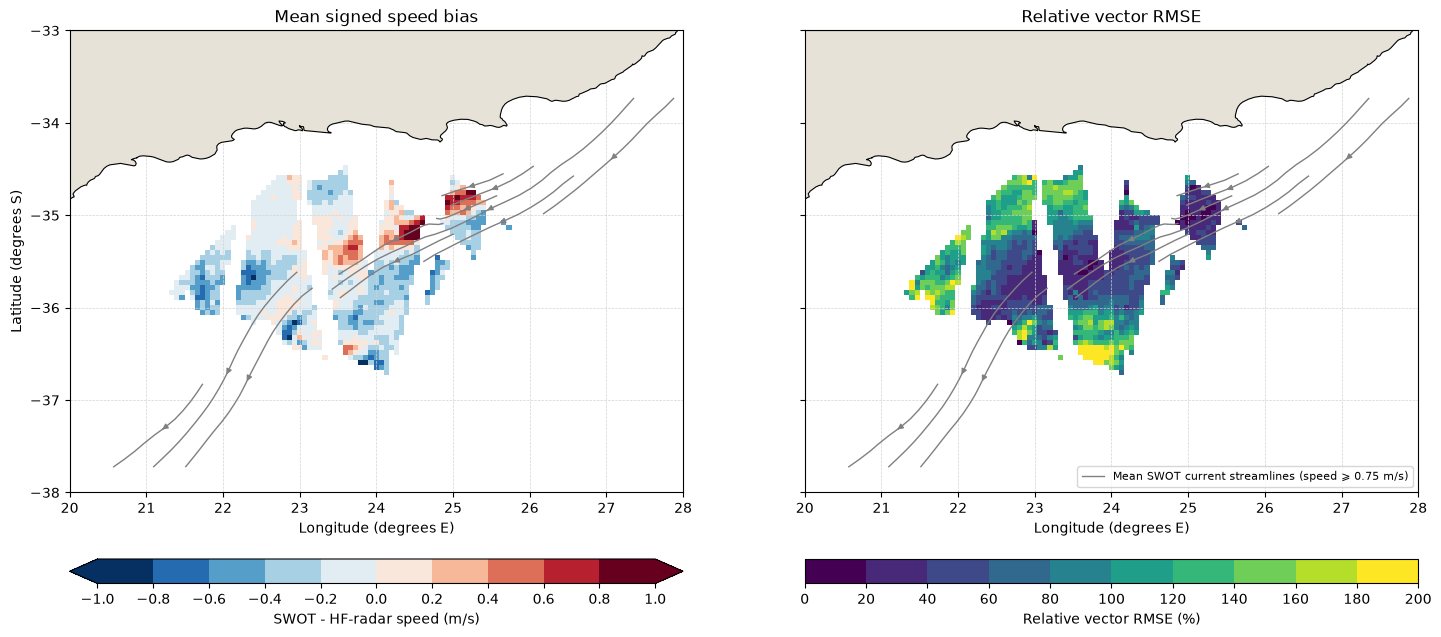

Grid cells with at least 1 paired comparison: 1,127 of 11,250
Median per-cell relative vector RMSE: 71.8%
Max per-cell relative vector RMSE: 200.0%
Mean spatial signed bias: -0.1168 m/s
Median spatial signed bias: -0.1323 m/s


In [39]:
# Accumulate per-cell relative vector RMSE and signed speed bias across matched observations.

STREAMLINE_SPEED_THRESHOLD = 0.75  # m/s; only show stronger mean currents

with xr.open_dataset(matched_triplets[0][1]) as ds0:
    error_grid_latitude = ds0['latitude'].values
    error_grid_longitude = ds0['longitude'].values

vector_squared_error_sum = np.zeros((error_grid_latitude.size, error_grid_longitude.size), dtype=float)
reference_speed_sum = np.zeros_like(vector_squared_error_sum)
signed_bias_sum = np.zeros_like(vector_squared_error_sum)
error_count = np.zeros_like(vector_squared_error_sum, dtype=int)

for _, file_coarse, file_radar in matched_triplets:
    with xr.open_dataset(file_coarse) as ds_coarse:
        coarse_u = ds_coarse['ugos_coarsened_masked'].values
        coarse_v = ds_coarse['vgos_coarsened_masked'].values
    with xr.open_dataset(file_radar) as ds_radar:
        radar_u = ds_radar['ewct_masked'].values
        radar_v = ds_radar['nsct_masked'].values

    coarse_speed = np.hypot(coarse_u, coarse_v)
    radar_speed = np.hypot(radar_u, radar_v)
    paired_valid = (
        np.isfinite(coarse_u)
        & np.isfinite(coarse_v)
        & np.isfinite(radar_u)
        & np.isfinite(radar_v)
    )
    vector_squared_error = (coarse_u - radar_u) ** 2 + (coarse_v - radar_v) ** 2
    reference_speed = (coarse_speed + radar_speed) / 2
    signed_speed_difference = coarse_speed - radar_speed

    vector_squared_error_sum[paired_valid] += vector_squared_error[paired_valid]
    reference_speed_sum[paired_valid] += reference_speed[paired_valid]
    signed_bias_sum[paired_valid] += signed_speed_difference[paired_valid]
    error_count[paired_valid] += 1

with np.errstate(invalid='ignore', divide='ignore'):
    vector_rmse_grid = np.sqrt(vector_squared_error_sum / error_count)
    mean_reference_speed_grid = reference_speed_sum / error_count
    signed_bias_grid = signed_bias_sum / error_count
vector_rmse_grid = np.where(error_count > 0, vector_rmse_grid, np.nan)
mean_reference_speed_grid = np.where(error_count > 0, mean_reference_speed_grid, np.nan)
signed_bias_grid = np.where(error_count > 0, signed_bias_grid, np.nan)

MIN_REFERENCE_SPEED = 0.05  # m/s; guard against dividing by near-zero mean speeds
with np.errstate(invalid='ignore', divide='ignore'):
    relative_vector_rmse_grid = 100 * vector_rmse_grid / mean_reference_speed_grid
relative_vector_rmse_grid = np.where(
    mean_reference_speed_grid >= MIN_REFERENCE_SPEED,
    relative_vector_rmse_grid,
    np.nan,
)

error_lat_edges = centre_edges(error_grid_latitude)
error_lon_edges = centre_edges(error_grid_longitude)

from concurrent.futures import ThreadPoolExecutor

swot_all_files = sorted(SWOT_L3_DIR.glob('SWOT_L3_LR_SSH_Expert_*.nc'))
current_grid_shape = vector_rmse_grid.shape


def accumulate_mean_current_chunk(file_paths):
    sum_u_chunk = np.zeros(current_grid_shape, dtype=float)
    sum_v_chunk = np.zeros(current_grid_shape, dtype=float)
    count_chunk = np.zeros(current_grid_shape, dtype=np.int64)
    for path in file_paths:
        try:
            with xr.open_dataset(path) as ds:
                if 'ugos_filtered' not in ds or 'vgos_filtered' not in ds:
                    continue
                lon = ds['longitude'].values
                lat = ds['latitude'].values
                u = ds['ugos_filtered'].values
                v = ds['vgos_filtered'].values
                quality_flag = ds['quality_flag'].values
        except Exception:
            continue
        valid = (
            np.isfinite(u) & np.isfinite(v)
            & np.isin(quality_flag, VALID_SWOT_QUALITY_FLAGS)
            & (lon >= PLOT_BBOX[0]) & (lon <= PLOT_BBOX[1])
            & (lat >= PLOT_BBOX[2]) & (lat <= PLOT_BBOX[3])
        )
        if not valid.any():
            continue
        sum_u_hist, _, _ = np.histogram2d(lat[valid], lon[valid], bins=(error_lat_edges, error_lon_edges), weights=u[valid])
        sum_v_hist, _, _ = np.histogram2d(lat[valid], lon[valid], bins=(error_lat_edges, error_lon_edges), weights=v[valid])
        count_hist, _, _ = np.histogram2d(lat[valid], lon[valid], bins=(error_lat_edges, error_lon_edges))
        sum_u_chunk += sum_u_hist
        sum_v_chunk += sum_v_hist
        count_chunk += count_hist.astype(np.int64)
    return sum_u_chunk, sum_v_chunk, count_chunk


num_current_workers = 16
current_chunk_size = int(np.ceil(len(swot_all_files) / num_current_workers))
current_file_chunks = [
    swot_all_files[i:i + current_chunk_size]
    for i in range(0, len(swot_all_files), current_chunk_size)
]

with ThreadPoolExecutor(max_workers=num_current_workers) as executor:
    current_results = list(executor.map(accumulate_mean_current_chunk, current_file_chunks))

sum_u_total = sum(r[0] for r in current_results)
sum_v_total = sum(r[1] for r in current_results)
count_total = sum(r[2] for r in current_results)

with np.errstate(invalid='ignore', divide='ignore'):
    mean_u_grid = sum_u_total / count_total
    mean_v_grid = sum_v_total / count_total
mean_u_grid = np.where(count_total > 0, mean_u_grid, np.nan)
mean_v_grid = np.where(count_total > 0, mean_v_grid, np.nan)
mean_speed_grid = np.hypot(mean_u_grid, mean_v_grid)

print(f'Mean current computed from {len(swot_all_files):,} SWOT L3 files ({(count_total > 0).sum():,} grid cells with data)')

speed_mask = mean_speed_grid >= STREAMLINE_SPEED_THRESHOLD
stream_u = np.where(speed_mask, mean_u_grid, np.nan)
stream_v = np.where(speed_mask, mean_v_grid, np.nan)

rmse_levels = np.arange(0, 220, 20)
rmse_cmap = plt.get_cmap('viridis', len(rmse_levels) - 1)
rmse_norm = mcolors.BoundaryNorm(rmse_levels, rmse_cmap.N)
signed_bias_step = 0.2
signed_bias_limit = max(float(np.nanpercentile(np.abs(signed_bias_grid), 99)), signed_bias_step)
signed_bias_limit = signed_bias_step * np.ceil(signed_bias_limit / signed_bias_step)
signed_bias_boundaries = np.arange(
    -signed_bias_limit,
    signed_bias_limit + signed_bias_step / 2,
    signed_bias_step,
)
signed_bias_cmap = plt.get_cmap('RdBu_r', len(signed_bias_boundaries) - 1)
signed_bias_norm = mcolors.BoundaryNorm(
    signed_bias_boundaries,
    signed_bias_cmap.N,
)

streamline_handle = plt.Line2D(
    [],
    [],
    color='grey',
    linewidth=1.0,
    label='Mean SWOT current streamlines (speed ⩾ 0.75 m/s)',
)

figure, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)

# Signed speed-bias map.
land.plot(ax=axes[0], color='#e7e2d8', zorder=2)
land.boundary.plot(ax=axes[0], color='black', linewidth=0.8, zorder=3)
bias_mesh = axes[0].pcolormesh(
    error_lon_edges,
    error_lat_edges,
    signed_bias_grid,
    cmap=signed_bias_cmap,
    norm=signed_bias_norm,
    zorder=1,
)
axes[0].streamplot(
    error_grid_longitude,
    error_grid_latitude,
    np.ma.masked_invalid(stream_u),
    np.ma.masked_invalid(stream_v),
    color='grey',
    linewidth=1.0,
    density=1.3,
    arrowsize=0.8,
    zorder=6,
)
axes[0].set_title('Mean signed speed bias')

# Relative vector RMSE map.
land.plot(ax=axes[1], color='#e7e2d8', zorder=2)
land.boundary.plot(ax=axes[1], color='black', linewidth=0.8, zorder=3)
rmse_mesh = axes[1].pcolormesh(
    error_lon_edges,
    error_lat_edges,
    relative_vector_rmse_grid,
    cmap=rmse_cmap,
    norm=rmse_norm,
    zorder=1,
)
axes[1].streamplot(
    error_grid_longitude,
    error_grid_latitude,
    np.ma.masked_invalid(stream_u),
    np.ma.masked_invalid(stream_v),
    color='grey',
    linewidth=1.0,
    density=1.3,
    arrowsize=0.8,
    zorder=6,
)
axes[1].set_title('Relative vector RMSE')
axes[1].legend(handles=[streamline_handle], loc='lower right', fontsize=8, framealpha=0.8)

for axis in axes:
    axis.set_xlim(PLOT_BBOX[0], PLOT_BBOX[1])
    axis.set_ylim(PLOT_BBOX[2], PLOT_BBOX[3])
    axis.set_xlabel('Longitude (degrees E)')
    axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
axes[0].set_ylabel('Latitude (degrees S)')

# Place compact horizontal colourbars below their corresponding subplots.
figure.subplots_adjust(left=0.06, right=0.98, bottom=0.24, top=0.90, wspace=0.14)
left_position = axes[0].get_position()
right_position = axes[1].get_position()
bias_colourbar_axis = figure.add_axes([
    left_position.x0,
    0.11,
    left_position.width,
    0.035,
])
rmse_colourbar_axis = figure.add_axes([
    right_position.x0,
    0.11,
    right_position.width,
    0.035,
])
figure.colorbar(
    bias_mesh,
    cax=bias_colourbar_axis,
    orientation='horizontal',
    ticks=signed_bias_boundaries,
    label='SWOT - HF-radar speed (m/s)',
    extend='both',
)
figure.colorbar(
    rmse_mesh,
    cax=rmse_colourbar_axis,
    orientation='horizontal',
    ticks=rmse_levels,
    label='Relative vector RMSE (%)',
)
plt.show()

print(f'Grid cells with at least 1 paired comparison: {(error_count > 0).sum():,} of {error_count.size:,}')
print(f'Median per-cell relative vector RMSE: {np.nanmedian(relative_vector_rmse_grid):.1f}%')
print(f'Max per-cell relative vector RMSE: {np.nanmax(relative_vector_rmse_grid):.1f}%')
print(f'Mean spatial signed bias: {np.nanmean(signed_bias_grid):+.4f} m/s')
print(f'Median spatial signed bias: {np.nanmedian(signed_bias_grid):+.4f} m/s')